# Analysis of xanf pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run xanf.

Major pipeline changes include more quality control mesasures focused on organelle channels (Endosome, endosome, and Endosome) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
import io
import matplotlib.pyplot as plt

# pip install python-pptx  (if not already installed)
from pptx import Presentation
from pptx.util import Inches, Pt

# ===========================================================================
# Figure capture: wrap plt.show so EVERY plot is grabbed, no per-call edits.
# ===========================================================================
_CAPTURED = []            # list of (title, png_bytes)
_CAPTURE_ON = True        # flip to False to pause capture for a cell


def _best_title(fig):
    """Pull a slide title from the figure: suptitle first, else first axes title."""
    # suptitle (used by scree / variant_pca)
    if getattr(fig, "_suptitle", None) is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return None


_orig_show = plt.show

def _capturing_show(*args, **kwargs):
    if _CAPTURE_ON:
        fig = plt.gcf()
        # skip empty figures (no axes / nothing drawn)
        if fig.axes:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
            buf.seek(0)
            _CAPTURED.append((_best_title(fig), buf.getvalue()))
    return _orig_show(*args, **kwargs)

plt.show = _capturing_show
print("Figure capture ON — every plt.show() will be collected.")


# ===========================================================================
# Build the deck (call once at the very end of the notebook).
# ===========================================================================
def build_pptx(path, captured=None, widescreen=True):
    captured = _CAPTURED if captured is None else captured
    prs = Presentation()
    if widescreen:
        prs.slide_width = Inches(13.333)
        prs.slide_height = Inches(7.5)
    blank = prs.slide_layouts[6]   # fully blank

    sw = prs.slide_width
    sh = prs.slide_height
    for title, png in captured:
        slide = prs.slides.add_slide(blank)
        top = Inches(0.1)
        if title:
            tb = slide.shapes.add_textbox(Inches(0.3), Inches(0.1),
                                          sw - Inches(0.6), Inches(0.6))
            tf = tb.text_frame
            tf.text = title
            tf.paragraphs[0].font.size = Pt(18)
            top = Inches(0.8)

        pic = slide.shapes.add_picture(io.BytesIO(png), Inches(0), top)
        # scale to fit the slide while preserving aspect ratio
        avail_w = sw
        avail_h = sh - top - Inches(0.1)
        scale = min(avail_w / pic.width, avail_h / pic.height)
        pic.width = int(pic.width * scale)
        pic.height = int(pic.height * scale)
        pic.left = int((sw - pic.width) / 2)   # center horizontally

    prs.save(path)
    print(f"wrote {len(captured)} slides -> {path}")


def restore_show():
    """Undo the monkeypatch (optional, e.g. before re-running interactively)."""
    plt.show = _orig_show
    print("Figure capture OFF — plt.show restored.")

Figure capture ON — every plt.show() will be collected.


## Load feature data
Load in feature data merged with metadata

In [3]:
xanf_organelle_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_xanf/xanf_organelle_output.parquet"
df = pd.read_parquet(xanf_organelle_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

df = df[df["Structure"] == "Recycling endosome"]

print(df.head())
print(df.columns.tolist())

                DAPI_filename  Nucleus_ID  \
2   r01c01f01p01-ch01t01.tiff         1.0   
5   r01c01f01p01-ch01t01.tiff         2.0   
8   r01c01f01p01-ch01t01.tiff         2.0   
11  r01c01f01p01-ch01t01.tiff         3.0   
14  r01c01f01p01-ch01t01.tiff         3.0   

                          Measurement_ID subdirectory  Row  Column  Frame  \
2   d5b2e3eb-3b91-4619-8c74-846bbcd92bd4       r01c01    1       1      1   
5   a9b2a502-ad2f-4ee9-85ba-10df3cea3b46       r01c01    1       1      1   
8   d5b2e3eb-3b91-4619-8c74-846bbcd92bd4       r01c01    1       1      1   
11  a9b2a502-ad2f-4ee9-85ba-10df3cea3b46       r01c01    1       1      1   
14  d5b2e3eb-3b91-4619-8c74-846bbcd92bd4       r01c01    1       1      1   

    Plane  Time           channel_filename  ... Batch_Info  Gene  Variant  \
2       1     1  r01c01f01p01-ch03t01.tiff  ...       None  TIA1    P351L   
5       1     1  r01c01f01p01-ch03t01.tiff  ...       None   FUS    R495X   
8       1     1  r01c01f01p01-ch03t

In [4]:
print(f"Total number of images: {df[['channel_filename', 'iNDI_Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of ROIs: {len(df)}")

Total number of images: 202881
Total number of ROIs: 1041047


# Primary analysis
## ROI level data
### Feature assessment and PCA loadings
Broad assessment of features before PCA

#### Helper functions

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# candidate regionprops features (from script 1)
CANDIDATE_FEATURES = [
    # ROI-level
    "area_px", "organelle_count", "average_organelle_area", "roi_occupancy",
    # pooled-pixel intensity
    "max_f_intensity", "sum_f_intensity", "mean_f_intensity",
    "median_f_intensity", "CoefOfVar_intensity",
    # per-object shape (use median as the robust center; add _std for spread)
    "area_median", "area_std",
    "perimeter_median", "eccentricity_median", "solidity_median",
    "extent_median", "axis_major_length_median", "axis_minor_length_median",
    "equivalent_diameter_area_median",
    # per-object intensity distribution
    "intensity_mean_median", "intensity_max_median", "intensity_min_median",
    # radial organization
    "dist_to_centroid_median", "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
# pruned set fed to PCA (after the |r|>0.9 review)
PCA_FEATURES = [
    "area_px", "organelle_count", "roi_occupancy",
    "mean_f_intensity", "CoefOfVar_intensity",
    "eccentricity_median", "solidity_median", "extent_median",
    "intensity_max_median",
    "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]


def feature_correlation(data, features=CANDIDATE_FEATURES,
                        title="Nuclear feature cross-correlation (raw)", show=True):
    """Pearson corr heatmap + list of |r|>0.9 pairs. Returns the corr matrix."""
    features = [c for c in features if c in data.columns]
    X = data[features].replace([np.inf, -np.inf], np.nan)
    corr = X.corr(method="pearson")

    if show:
        plt.figure(figsize=(9, 7))
        im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.xticks(range(len(features)), features, rotation=90, fontsize=8)
        plt.yticks(range(len(features)), features, fontsize=8)
        plt.colorbar(im, label="Pearson r")
        plt.title(title)
        plt.tight_layout(); plt.show()

    hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(features)
             for b in features[i + 1:] if hi.loc[a, b]]
    print("Highly correlated pairs (|r| > 0.9):")
    for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {r:+.3f}  {a:22s} {b}")
    return corr


def fit_pca(data, features=PCA_FEATURES, add_aspect_ratio=True,
            show_scree=True, show_loadings=True, label=""):
    """Add aspect_ratio, drop NaN/inf, scale, and fit PCA.

    Operates on a COPY -- does not mutate the input or any global. Returns
    (scored_df, pca, features_used) where scored_df has PC1..PCn columns.
    """
    data = data.copy()
    if add_aspect_ratio and {"axis_minor_length", "axis_major_length"} <= set(data.columns):
        data["aspect_ratio"] = data["axis_minor_length"] / data["axis_major_length"]

    features = [c for c in features if c in data.columns]
    print(f"[{label}] using FEATURES:", features)

    before = len(data)
    X_df = data[features].replace([np.inf, -np.inf], np.nan)
    keep = X_df.notna().all(axis=1)
    data = data[keep].reset_index(drop=True)
    X_df = X_df[keep].reset_index(drop=True)
    print(f"[{label}] dropped {before - len(data)} rows with NaN/inf; {len(data)} remain")

    X = StandardScaler().fit_transform(X_df.values)
    pca = PCA(n_components=len(features))
    scores = pca.fit_transform(X)
    for i in range(scores.shape[1]):
        data[f"PC{i+1}"] = scores[:, i]

    ev = pca.explained_variance_ratio_
    print(f"[{label}] EVR:", ev.round(3))
    print(f"[{label}] cumulative:", np.cumsum(ev).round(3))

    if show_scree:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].bar(range(1, len(ev) + 1), ev)
        ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
        ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
        ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
        ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
        if label:
            fig.suptitle(f"{label} — scree")
        plt.tight_layout(); plt.show()

    if show_loadings:
        loadings = pd.DataFrame(
            pca.components_.T, index=features,
            columns=[f"PC{i+1}" for i in range(len(features))],
        )
        print(loadings.round(3))
        n_show = min(6, len(features))
        plt.figure(figsize=(1.6 * n_show, 0.4 * len(features) + 1))
        im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r",
                        vmin=-1, vmax=1, aspect="auto")
        plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
        plt.yticks(range(len(features)), features, fontsize=9)
        plt.colorbar(im, label="Loading")
        plt.title(f"{label} — Nuclear PCA loadings" if label else "Nuclear PCA loadings")
        plt.tight_layout(); plt.show()

    return data, pca, features


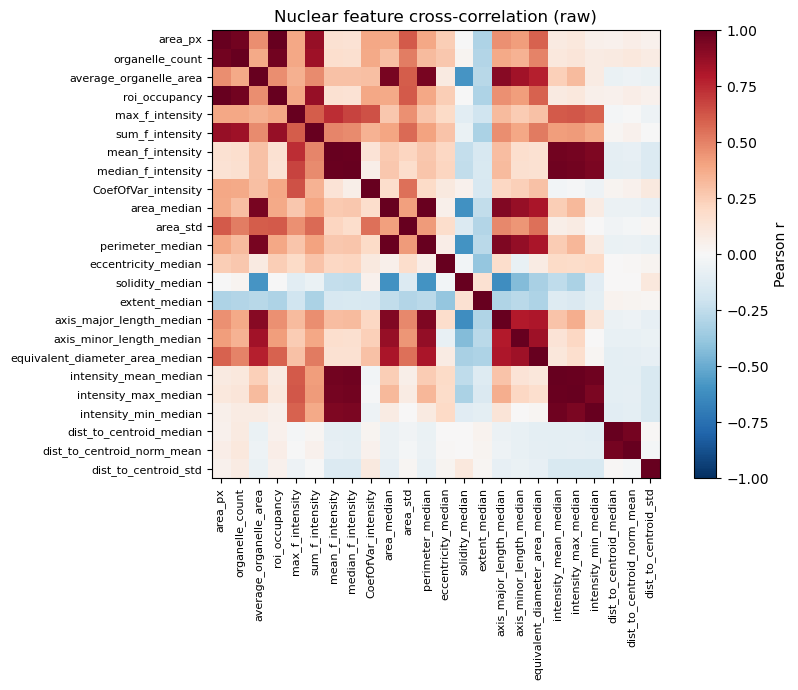

Highly correlated pairs (|r| > 0.9):
  +0.991  area_median            perimeter_median
  +0.990  mean_f_intensity       median_f_intensity
  +0.988  intensity_mean_median  intensity_max_median
  +0.973  intensity_mean_median  intensity_min_median
  +0.972  median_f_intensity     intensity_mean_median
  +0.964  median_f_intensity     intensity_max_median
  +0.962  area_px                organelle_count
  +0.962  organelle_count        roi_occupancy
  +0.961  mean_f_intensity       intensity_mean_median
  +0.956  mean_f_intensity       intensity_max_median
  +0.953  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.950  average_organelle_area area_median
  +0.947  average_organelle_area perimeter_median
  +0.941  median_f_intensity     intensity_min_median
  +0.938  intensity_max_median   intensity_min_median
  +0.933  mean_f_intensity       intensity_min_median
  +0.933  perimeter_median       axis_major_length_median
  +0.925  area_median            axis_major_length_median
  +0.

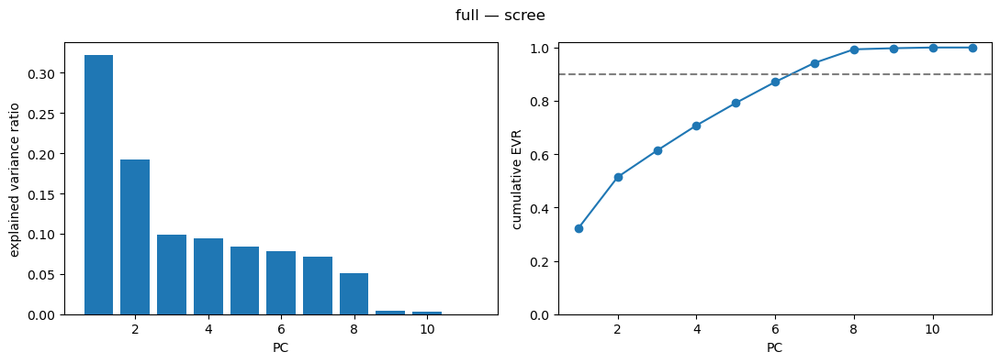

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.496 -0.172 -0.144  0.005 -0.137 -0.040 -0.153   
organelle_count             0.492 -0.173 -0.134 -0.004 -0.059  0.001 -0.178   
roi_occupancy               0.496 -0.172 -0.144  0.005 -0.137 -0.040 -0.153   
mean_f_intensity            0.211  0.573 -0.159 -0.200  0.190  0.169  0.025   
CoefOfVar_intensity         0.259 -0.123 -0.089 -0.222  0.226 -0.088  0.872   
eccentricity_median         0.229  0.114  0.628  0.143  0.149  0.342 -0.076   
solidity_median            -0.052 -0.338 -0.005 -0.318  0.044  0.824  0.013   
extent_median              -0.256 -0.089 -0.597 -0.236  0.105  0.102 -0.206   
intensity_max_median        0.180  0.606 -0.154 -0.142  0.145  0.107 -0.111   
dist_to_centroid_norm_mean  0.035 -0.132 -0.246  0.656  0.678  0.115 -0.027   
dist_to_centroid_std        0.019 -0.217  0.270 -0.532  0.597 -0.359 -0.314   

                              PC8    PC9   PC10   P

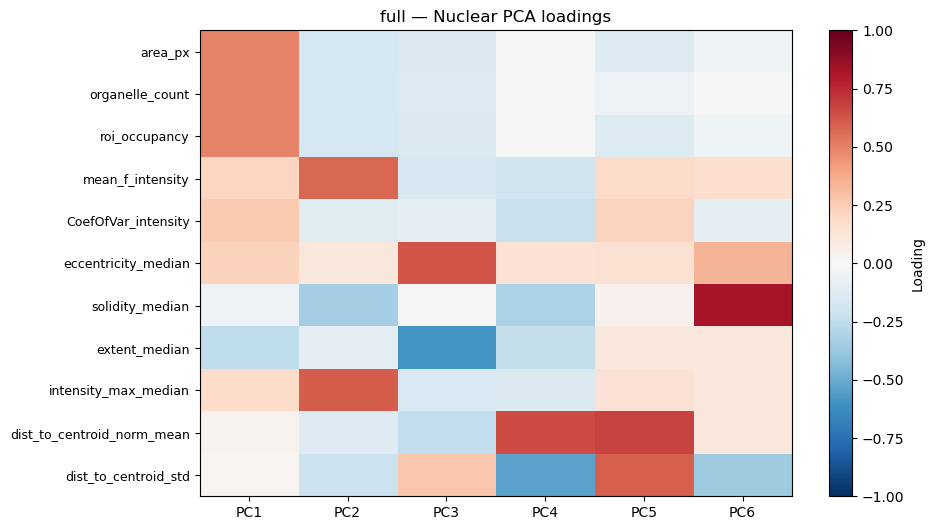

In [6]:
feature_correlation(df)
df, pca, FEATURES = fit_pca(df, label="full")

### PCA plots
Assessment of ROI level data for features

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey


# ===========================================================================
# Palettes
# ===========================================================================
def make_palette(values, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)):
    """Stable {value: color} mapping for a categorical column, derived from
    the data (not a hardcoded set). Sorted so colors are reproducible."""
    vals = sorted(pd.Series(values).dropna().unique())
    raw = glasbey.create_palette(palette_size=max(len(vals), 1),
                                 hue_bounds=hue_bounds, chroma_bounds=chroma_bounds)
    cmap = ListedColormap(raw)
    pal = {v: cmap(i) for i, v in enumerate(vals)}
    return pal


# high-cardinality fallback for genotype-like columns with no fixed mapping
_GENO_RAW = glasbey.create_palette(palette_size=64, hue_bounds=(0.0, 360.0),
                                   chroma_bounds=(40, 90))
GENO_COLORS = [ListedColormap(_GENO_RAW)(i) for i in range(64)]


def check_palette_coverage(data, col, palette):
    """Warn about values present in the data but missing from the palette."""
    present = set(data[col].dropna().unique())
    missing = present - set(palette)
    print(f"[warning] {col} values with no color: {sorted(missing)}" if missing
          else f"All {len(present)} {col} values have a color.")


# ===========================================================================
# Scatter: one PCA panel colored by a categorical column
# ===========================================================================
def pca_scatter(data, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True, shuffle=True, random_state=0):
    """PCA scatter colored by `color_col`.

    palette : optional {value: color} dict. If None, Gene_Var_Type uses the
              glasbey genotype colors and everything else falls back to husl.
    shuffle : plot rows in random order so no single group sits on top.
    """
    if shuffle:
        data = data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = data[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [GENO_COLORS[i % len(GENO_COLORS)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(data.loc[m, pcx], data.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return ax


# ===========================================================================
# Centroid overlay: per-group centroids over a faint background cloud
# ===========================================================================
def centroid_overlay(data, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = data.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else data
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = data.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    colors = ([palette.get(c, "#808080") for c in cats] if palette
              else sns.color_palette("husl", n_colors=len(cats)))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent


# ===========================================================================
# Convenience: a standard panel set for one scored frame
# ===========================================================================
def scatter_panels(data, specs, label="Recycling endosome", s=2, alpha=0.15, figsize=(12, 7)):
    """Run pca_scatter for several columns in one call.

    specs : list of (column, palette_or_None). Pass a palette dict for columns
            you want stable colors on (plate, batch); None lets the function
            pick (glasbey for Gene_Var_Type, husl otherwise).
    """
    for col, pal in specs:
        pca_scatter(data, col, palette=pal, s=s, alpha=alpha, figsize=figsize,
                    legend_ncol=2 if col in ("Gene_Var_Type", "Genotype_Name") else 1,
                    title=f"{label} — {col}")


# --- usage -----------------------------------------------------------------
# build palettes once from whatever frame you're plotting:
# plate_pal = make_palette(df["iNDI_Plate_ID"])
# batch_pal = make_palette(df["Batch"])
# check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
#
# # single calls, anywhere later in the script -- no global dependencies:
# pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7),
#             title="Nuclei — iNDI_Plate_ID")
# pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
#             title="Nuclei — Gene_Var_Type")
#
# # or the whole standard set at once:
# scatter_panels(df, [
#     ("iNDI_Plate_ID", plate_pal),
#     ("Source",        None),
#     ("Batch",         batch_pal),
#     ("Asp PosID",     None),
#     ("Genotype_Name", None),
# ])
#
# centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal,
#                  figsize=(12, 7), title="Per-experiment medians (by plate)")
# cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
# print("Std of per-experiment centroids (batch magnitude):")
# print(cent.std().round(3))

All 12 iNDI_Plate_ID values have a color.


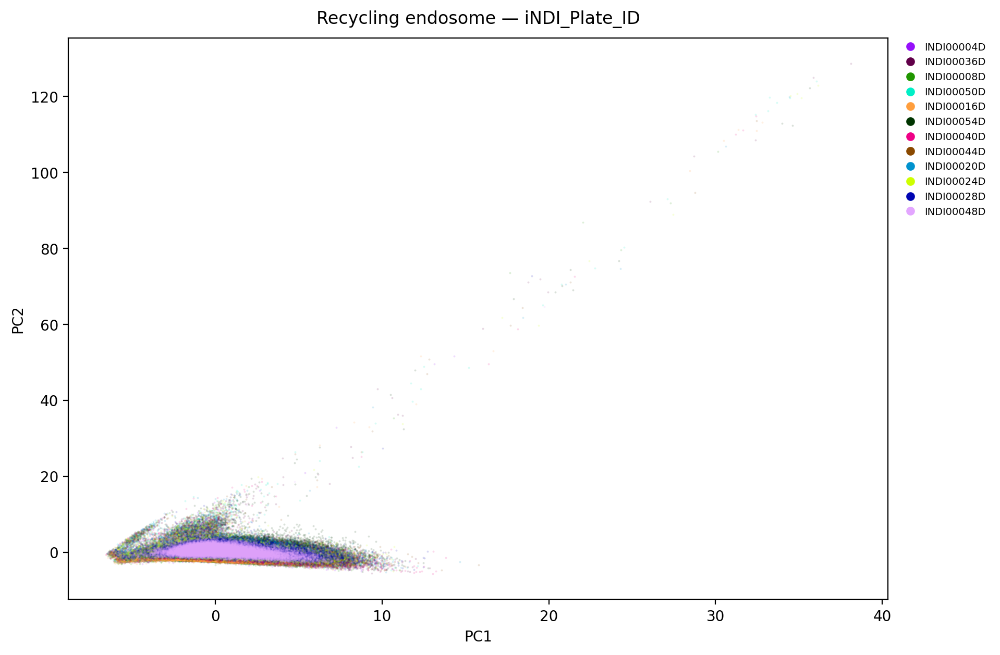

All 5 Batch values have a color.


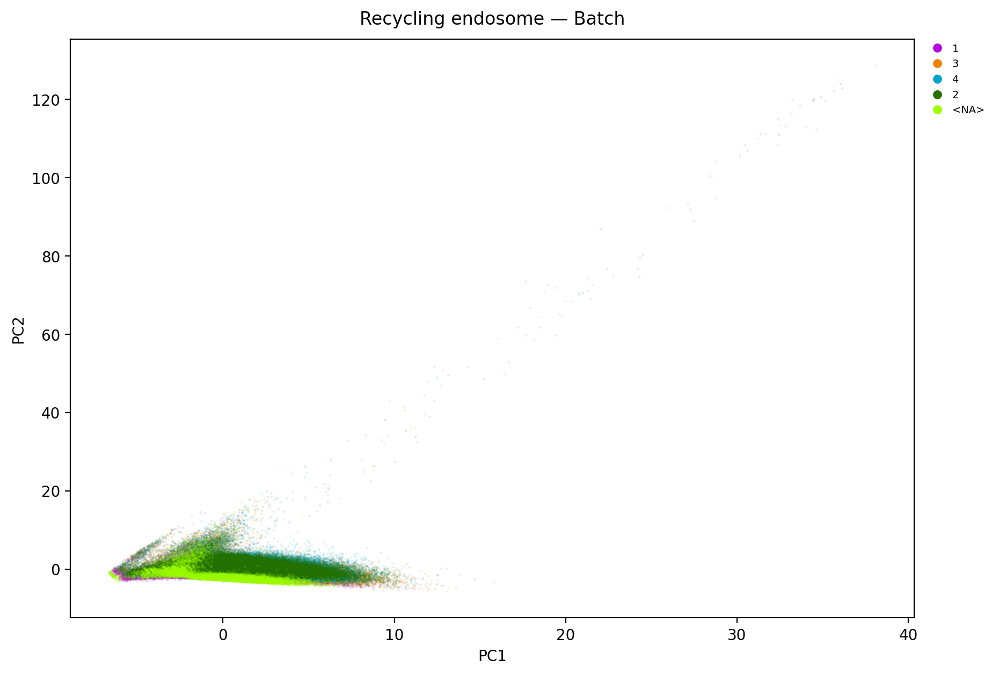

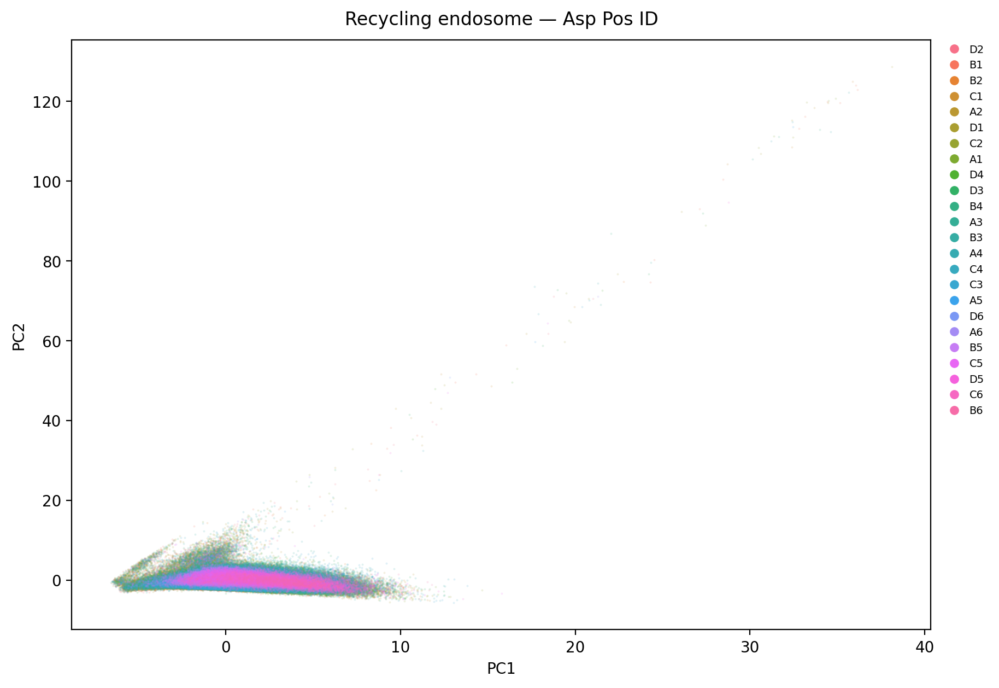

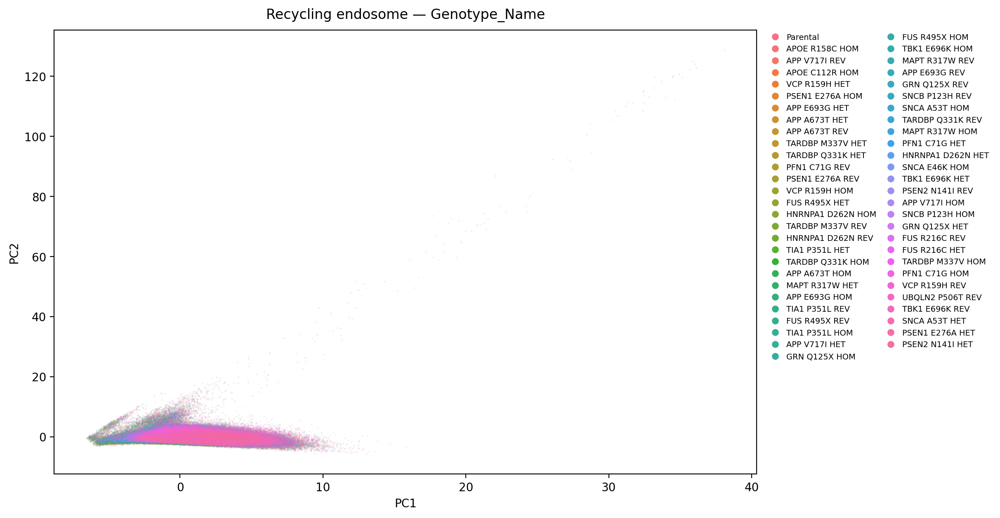

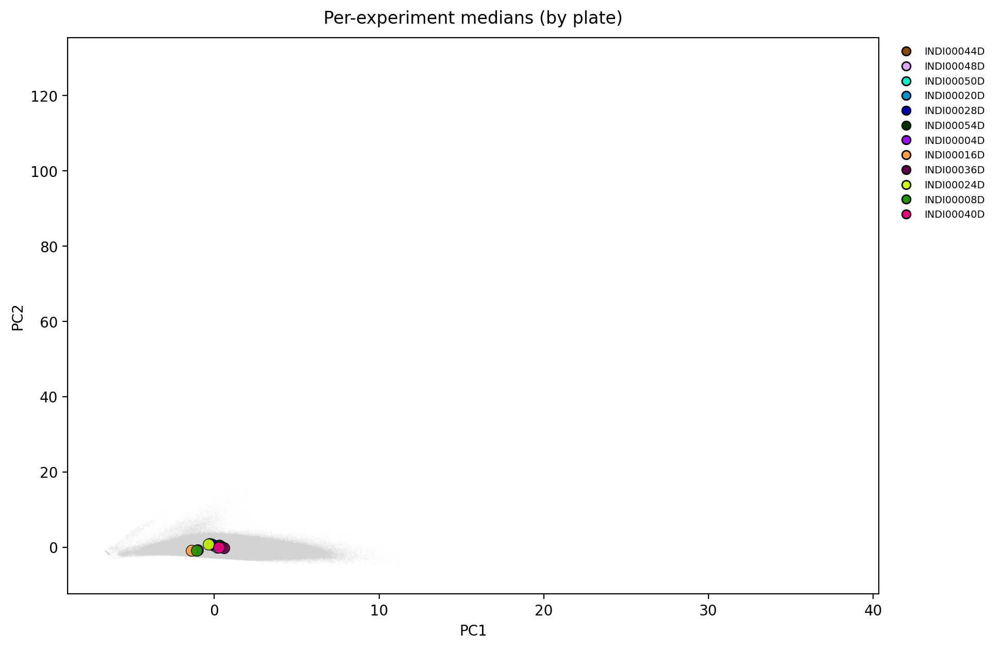

Std of per-experiment centroids (batch magnitude):
PC1    0.620
PC2    0.883
PC3    0.068
dtype: float64


In [8]:
plate_pal = make_palette(df["iNDI_Plate_ID"])
check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Recycling endosome — iNDI_Plate_ID")

batch_palette = make_palette(df["Batch"])
check_palette_coverage(df, "Batch", batch_palette)
pca_scatter(df, "Batch", palette=batch_palette, figsize=(12, 7),title="Recycling endosome — Batch")

pca_scatter(df, "Asp PosID", figsize=(12, 7),title="Recycling endosome — Asp Pos ID")

pca_scatter(df, "Genotype_Name", figsize=(13, 7), legend_ncol=2, title="Recycling endosome — Genotype_Name")

centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

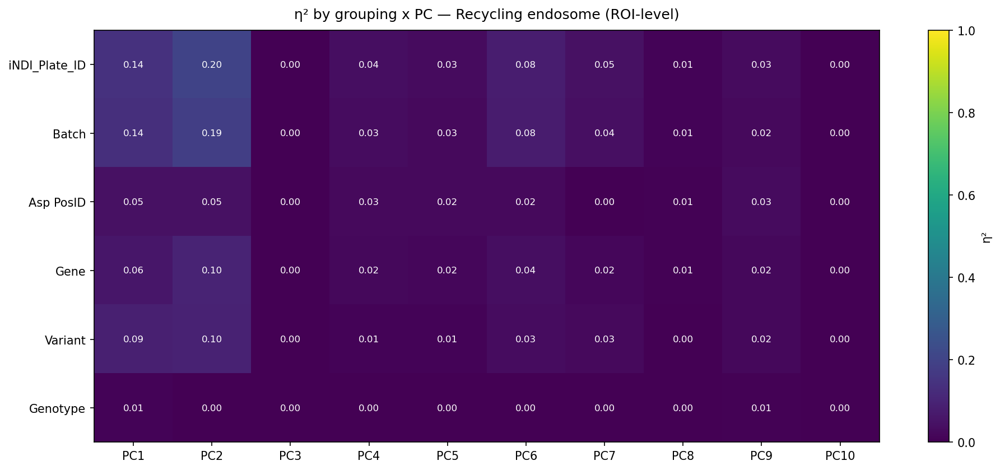

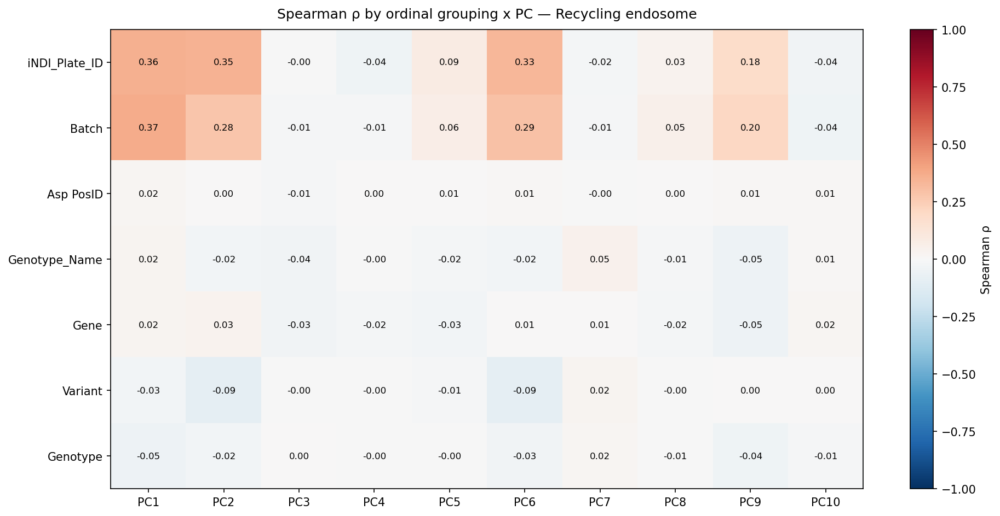

In [9]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — Recycling endosome (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Batch", "Asp PosID", "Genotype_Name", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — Recycling endosome")

[facet] 22 (gene, variant) pairs; 300086 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 20277 variant + 300086 parental rows


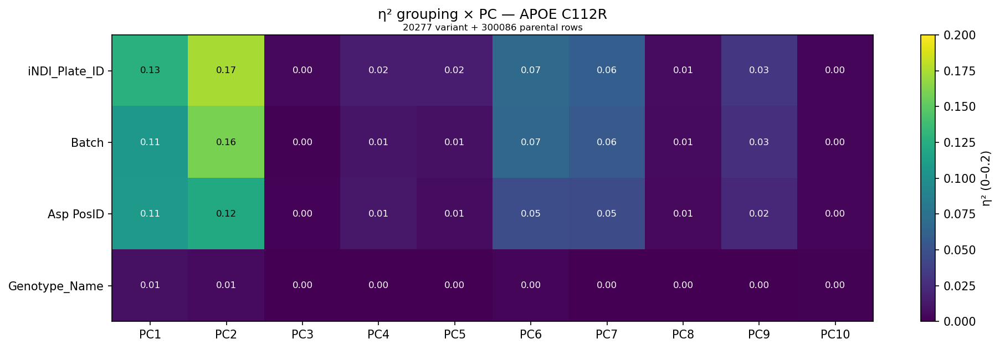

  APOE / R158C: 27027 variant + 300086 parental rows


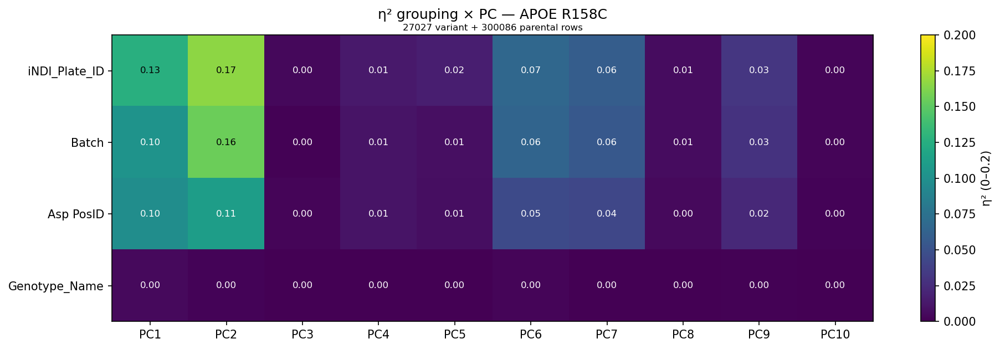

  APP / A673T: 52950 variant + 300086 parental rows


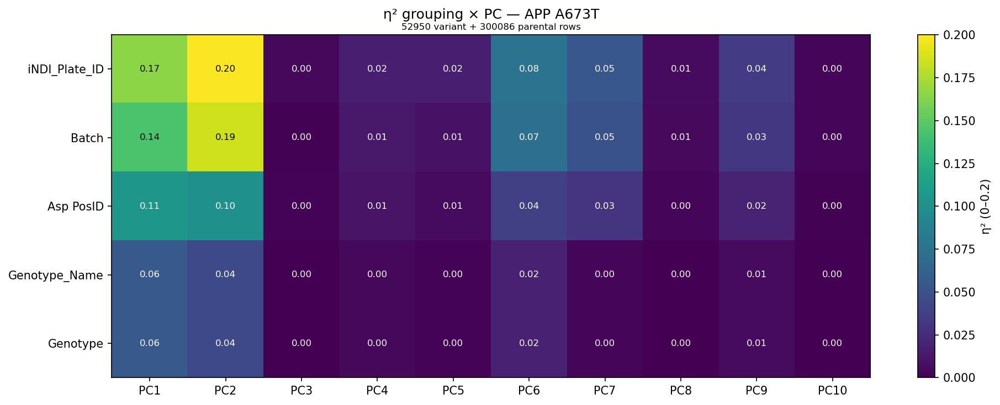

  APP / E693G: 48199 variant + 300086 parental rows


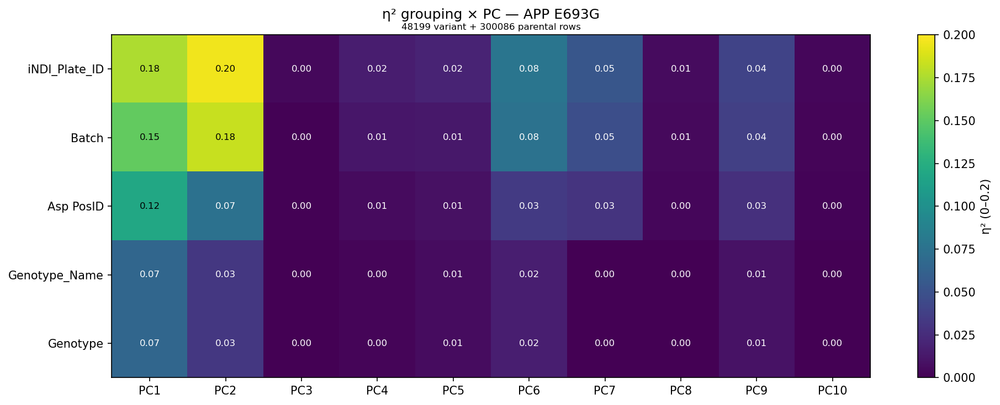

  APP / V717I: 43274 variant + 300086 parental rows


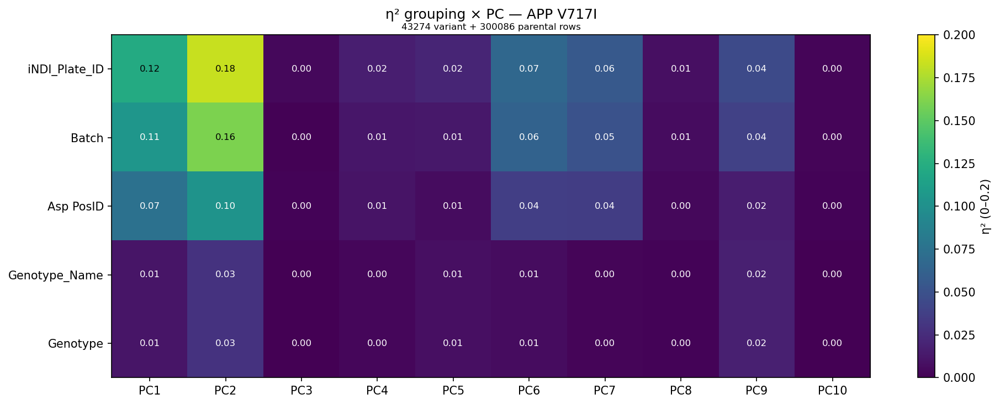

  FUS / R216C: 14061 variant + 300086 parental rows


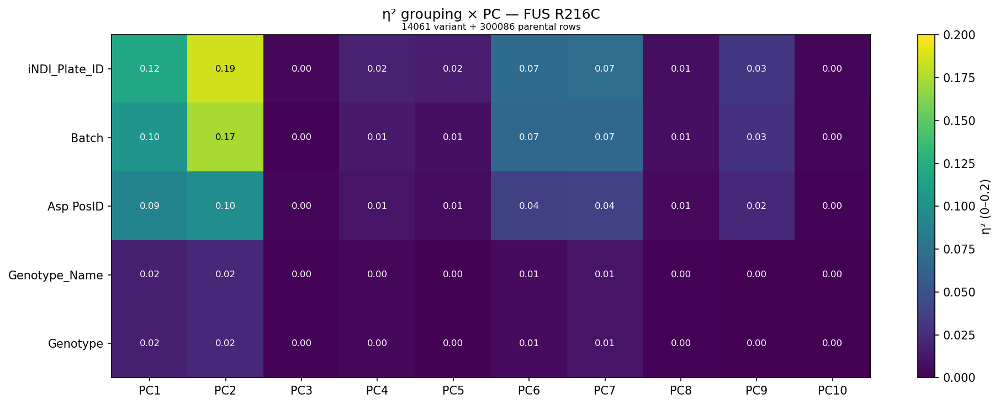

  FUS / R495X: 47695 variant + 300086 parental rows


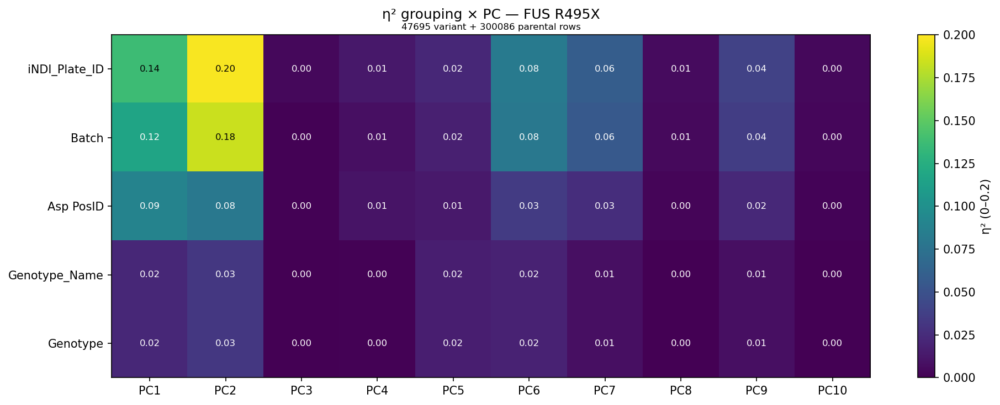

  GRN / Q125X: 34932 variant + 300086 parental rows


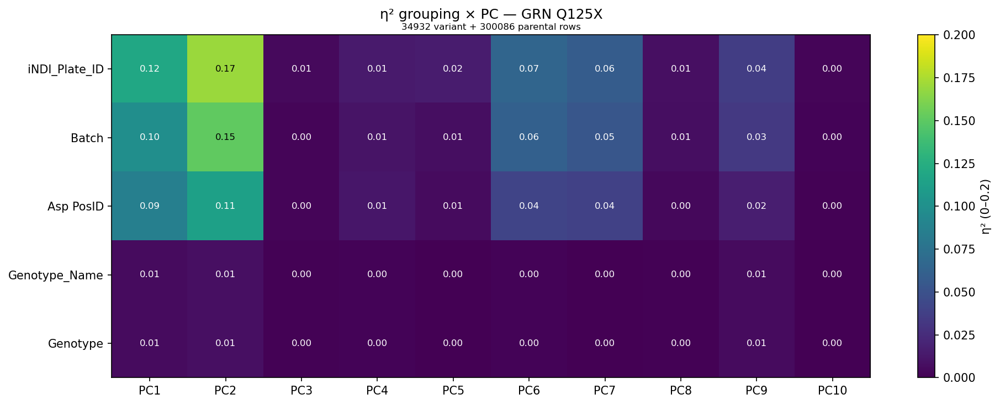

  HNRNPA1 / D262N: 44250 variant + 300086 parental rows


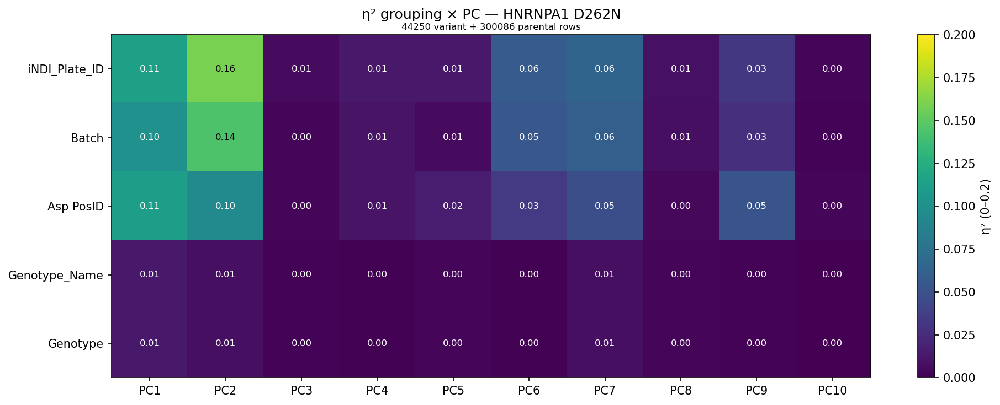

  MAPT / R406W: 40445 variant + 300086 parental rows


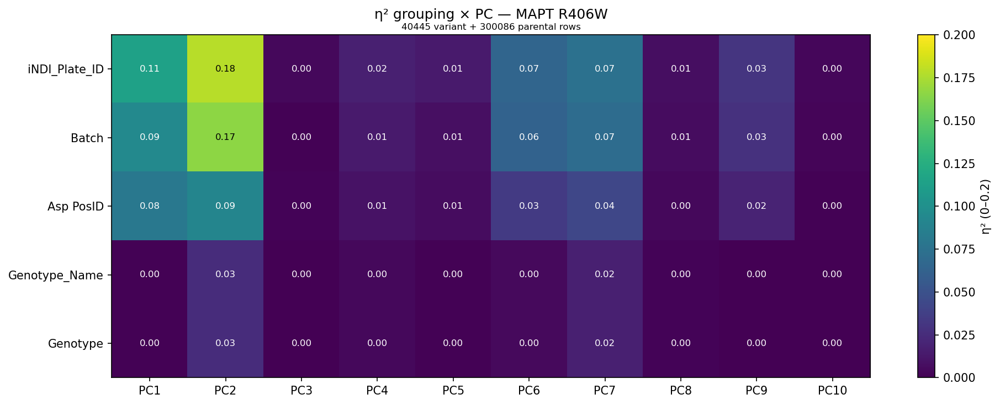

  PFN1 / C71G: 34635 variant + 300086 parental rows


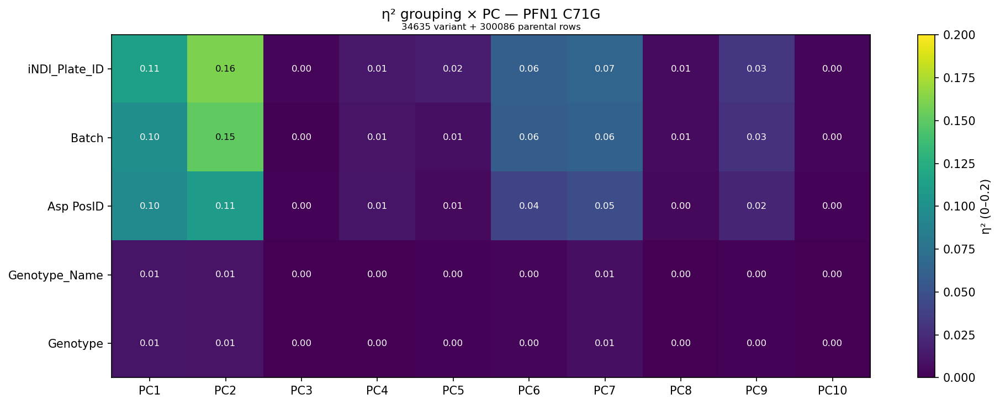

  PSEN1 / E276A: 38304 variant + 300086 parental rows


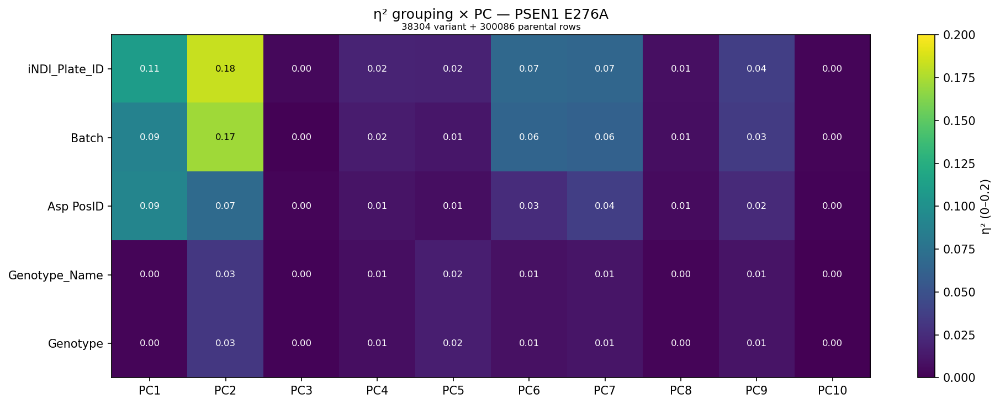

  PSEN2 / N141I: 10056 variant + 300086 parental rows


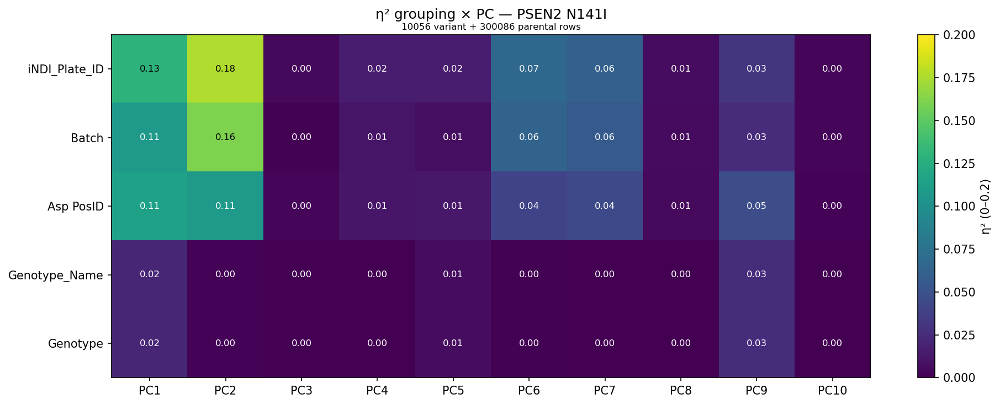

  SNCA / A53T: 14680 variant + 300086 parental rows


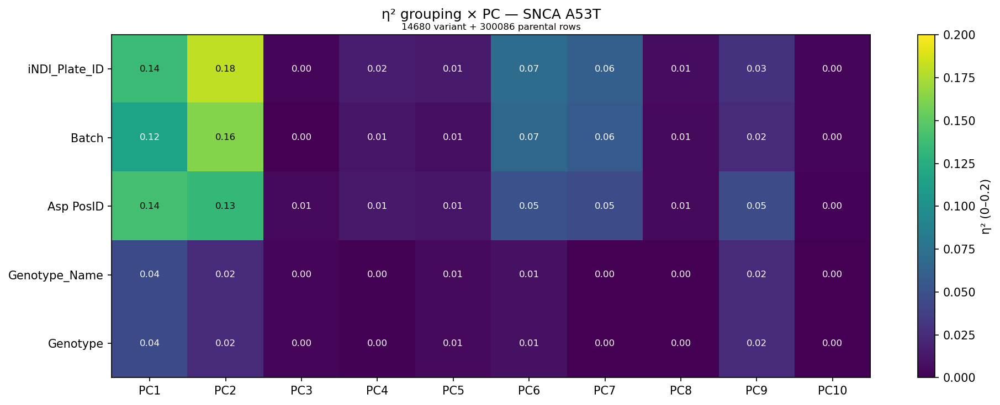

  SNCA / E46K: 9295 variant + 300086 parental rows


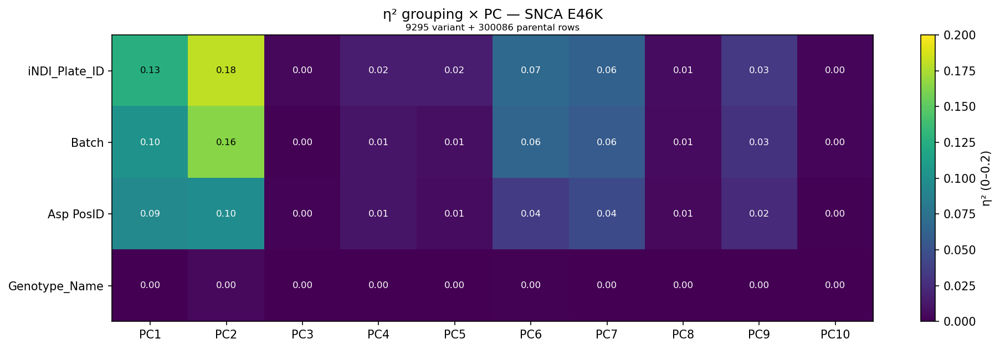

  SNCB / P123H: 19874 variant + 300086 parental rows


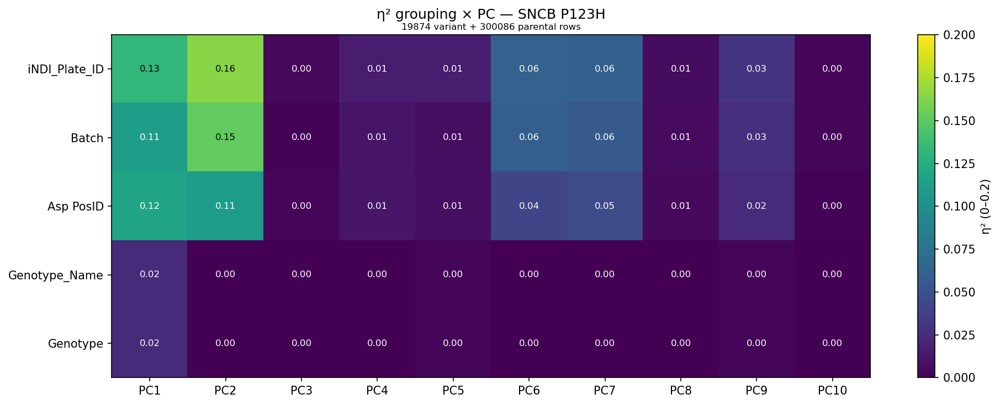

  TARDBP / M337V: 41276 variant + 300086 parental rows


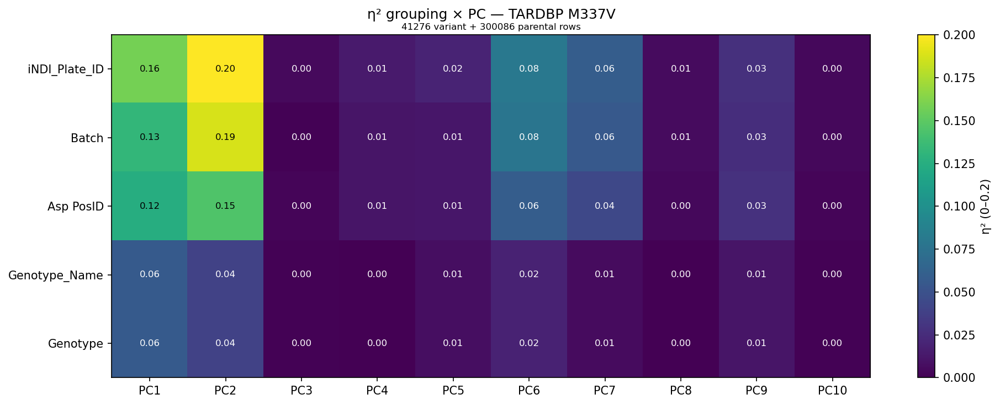

  TARDBP / Q331K: 45201 variant + 300086 parental rows


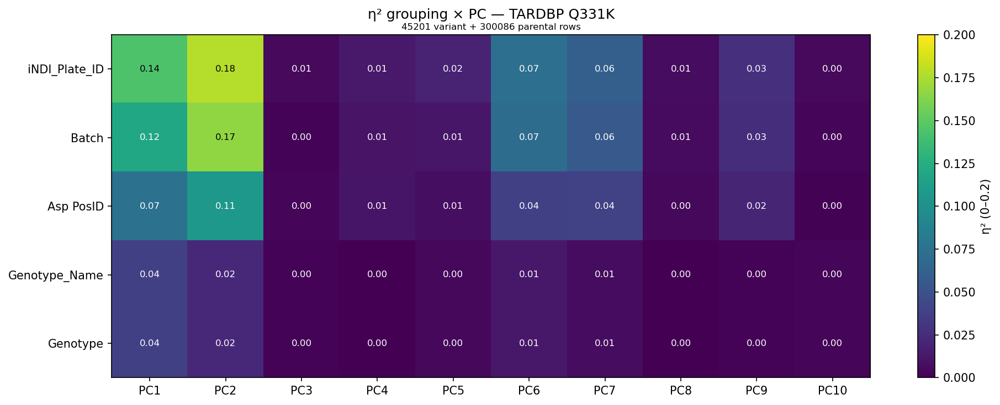

  TBK1 / E696K: 25799 variant + 300086 parental rows


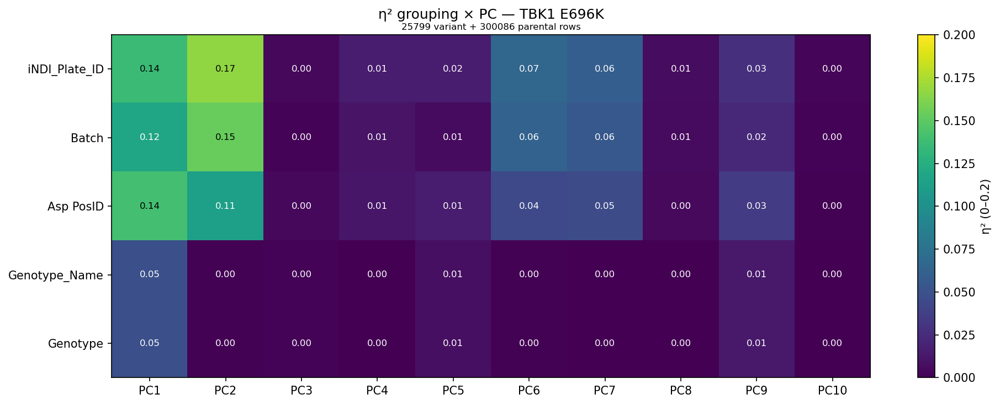

  TIA1 / P351L: 47744 variant + 300086 parental rows


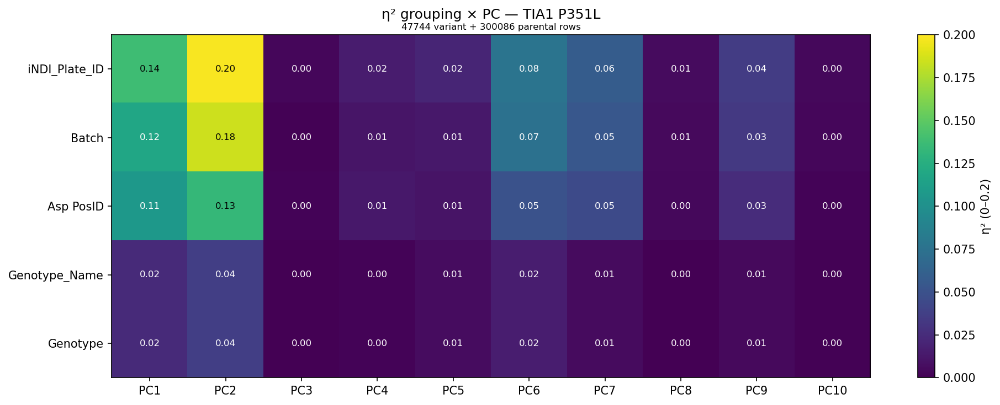

  UBQLN2 / P506T: 3388 variant + 300086 parental rows


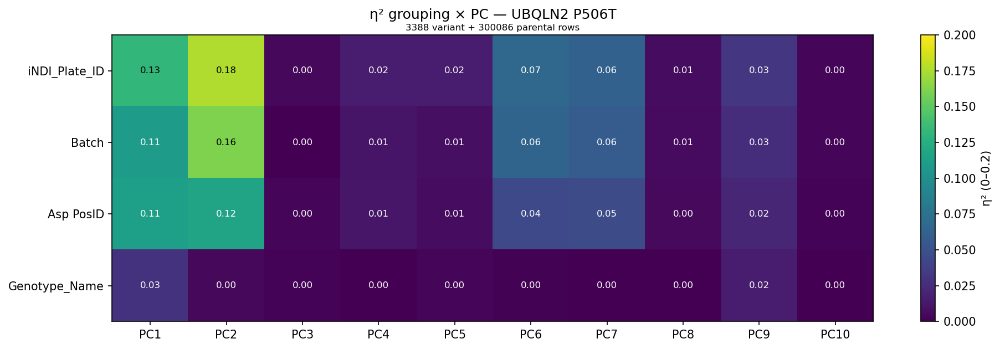

  VCP / R159H: 42722 variant + 300086 parental rows


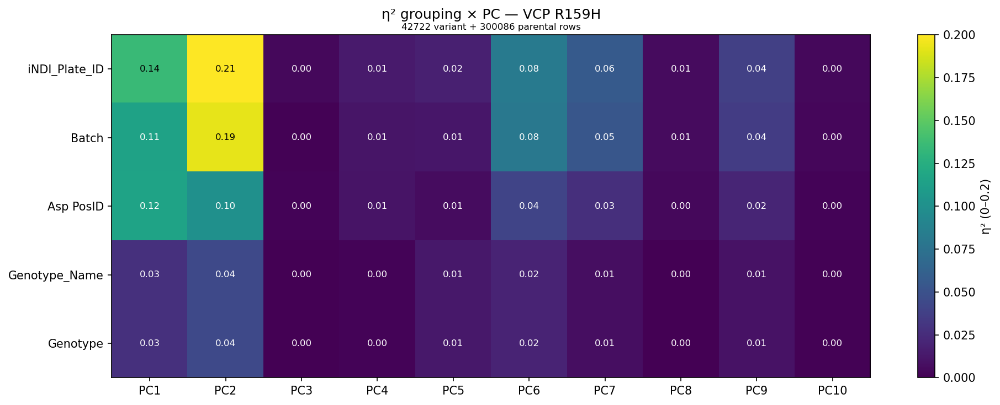

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- eta_squared ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["iNDI_Plate_ID", "Batch", "Asp PosID", "Genotype_Name", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_by_gene_variant(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene_variant(df, GROUP_COLS, n_pcs=10, vmax=0.2)

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 202881 rows (24133 images)
[full] well-level: 3930 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 3930 remain
[full well] EVR: [0.424 0.249 0.165 0.055 0.05  0.026 0.022 0.007 0.002 0.    0.   ]
[full well] cumulative: [0.424 0.674 0.838 0.894 0.943 0.969 0.991 0.998 1.    1.    1.   ]


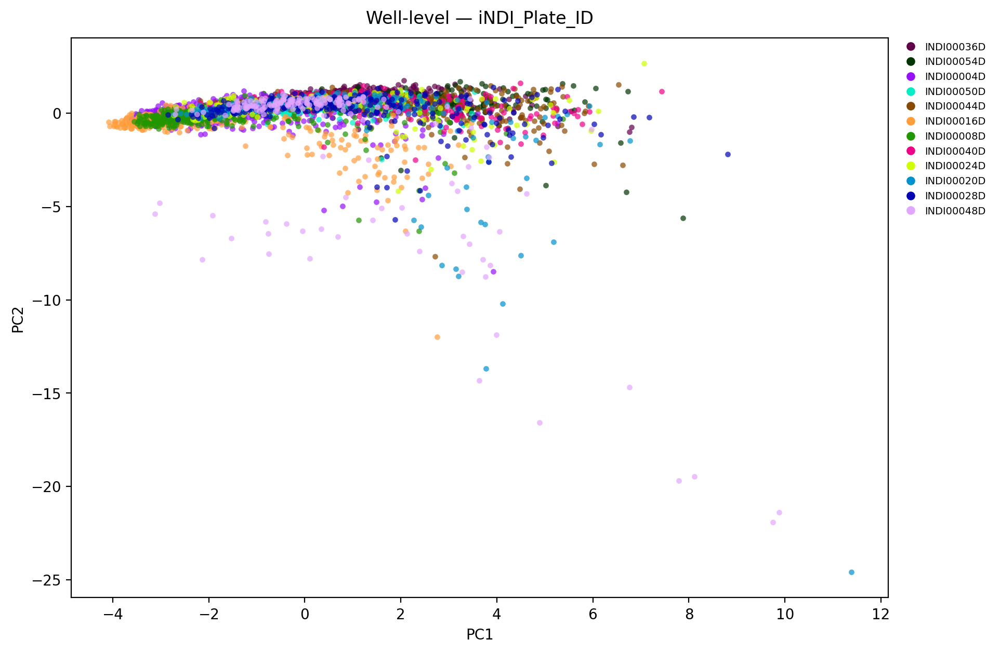

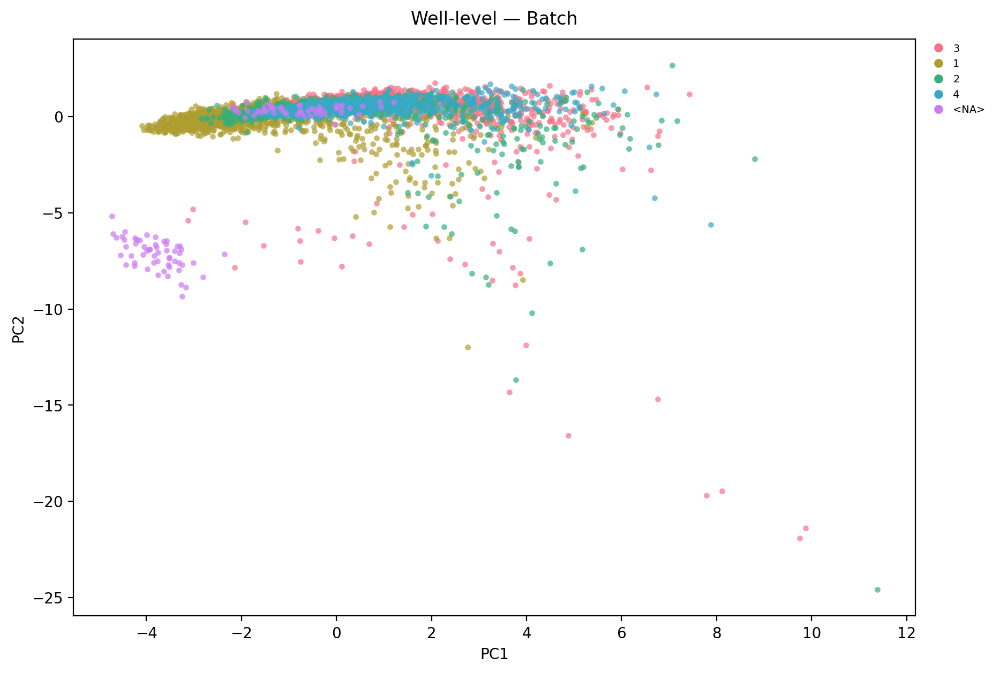

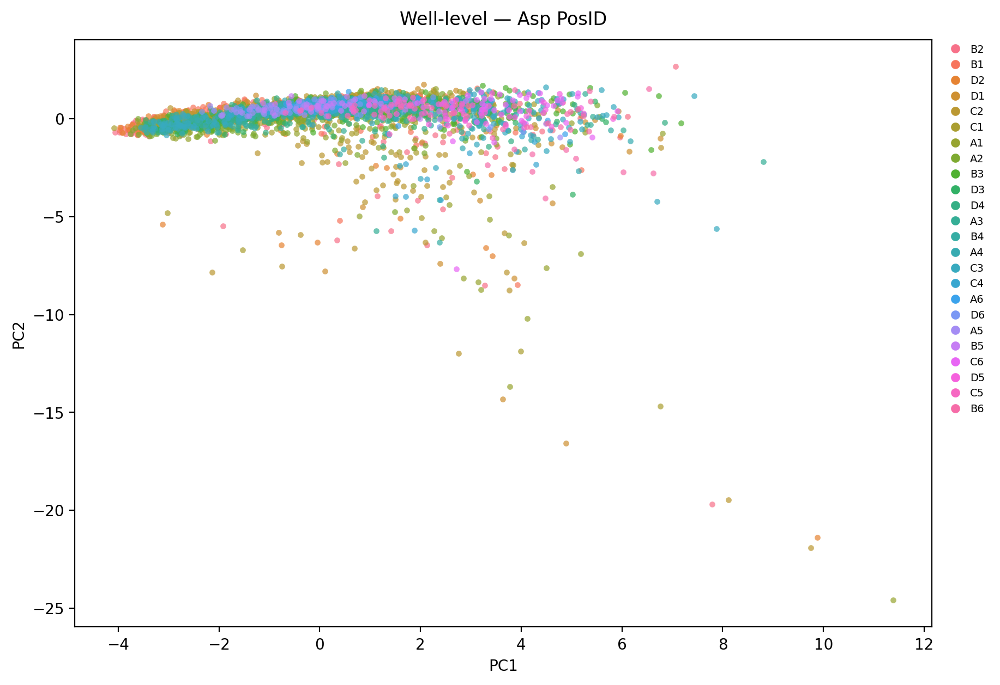

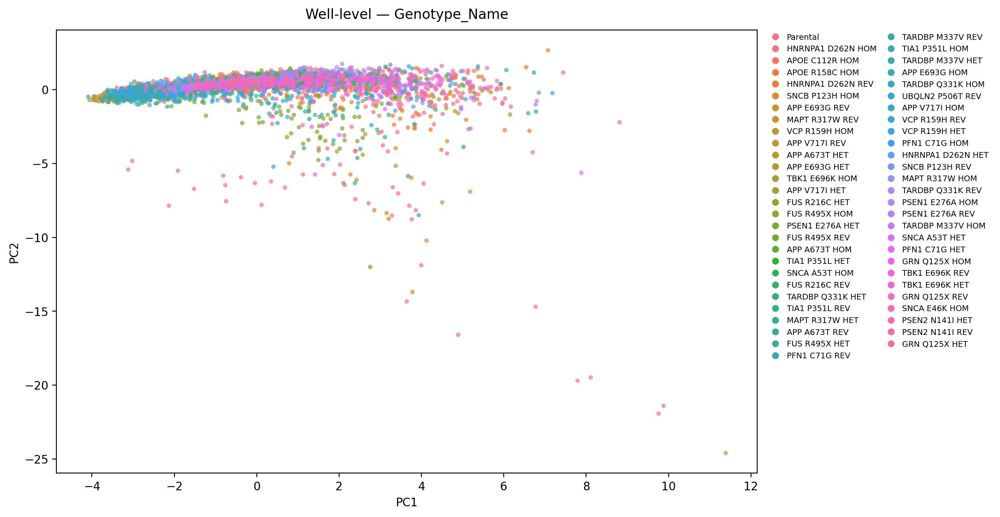

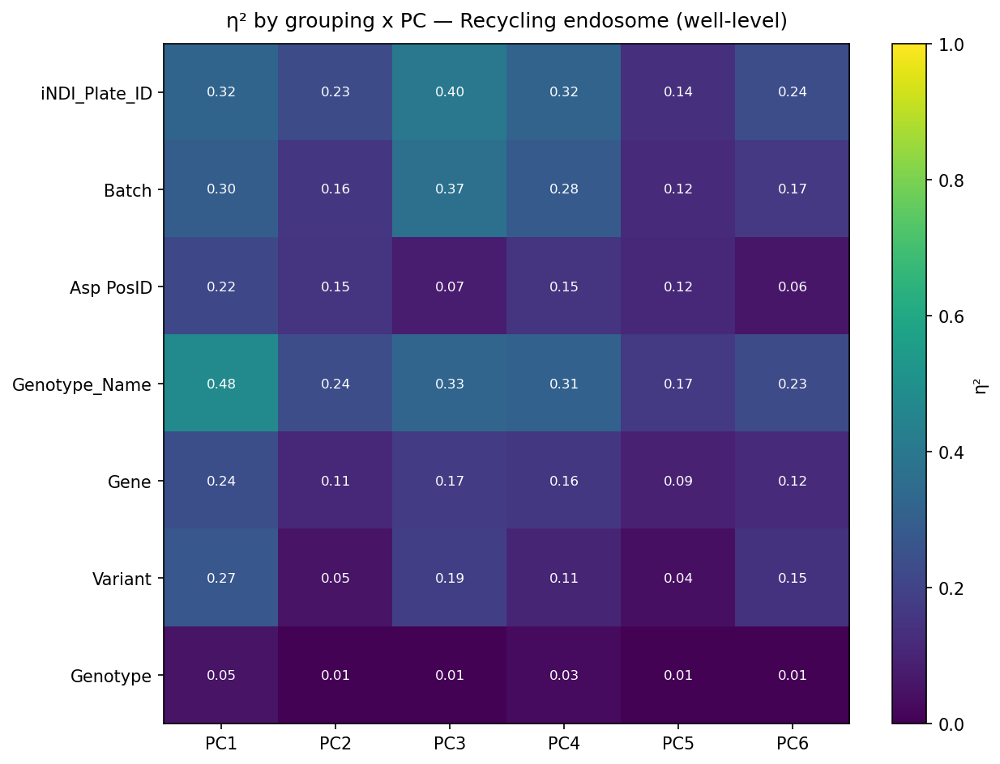

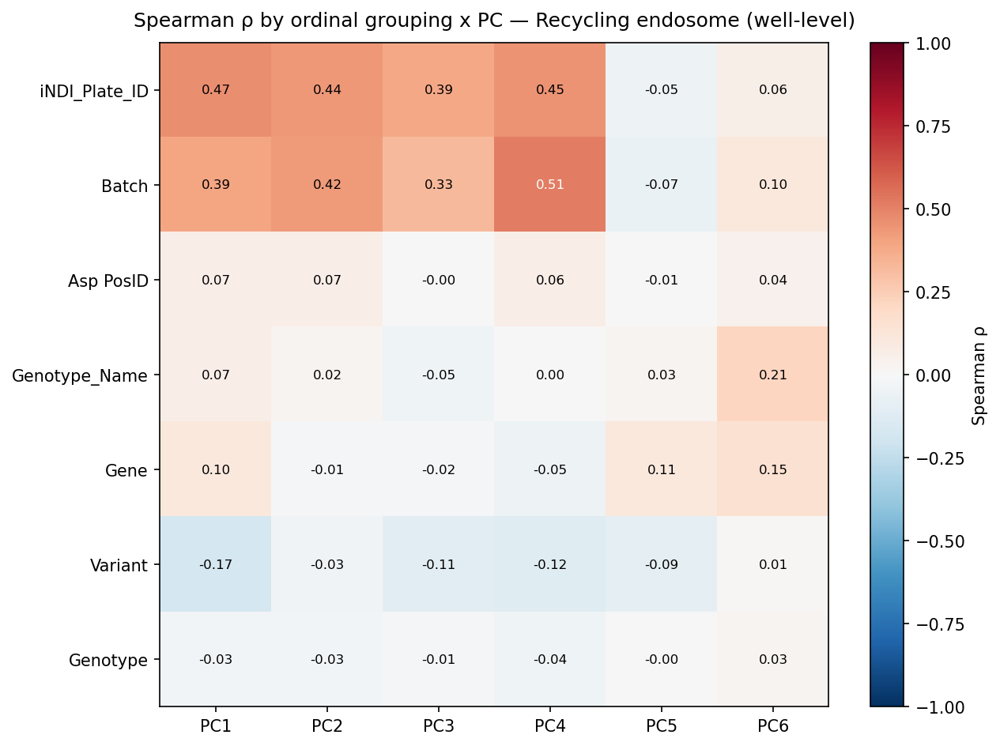

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.467956,0.435607,0.387463,0.451631,-0.048036,0.056817
Batch,0.393007,0.423325,0.325044,0.513795,-0.065319,0.103310
Asp PosID,0.068659,0.066297,-0.000010,0.064015,-0.007285,0.040932
Genotype_Name,0.067494,0.024114,-0.045883,0.000710,0.026771,0.214197
Gene,0.102197,-0.013406,-0.015194,-0.049512,0.107726,0.153579
Variant,-0.174965,-0.033282,-0.105380,-0.121448,-0.088537,0.011158
Genotype,-0.030747,-0.030563,-0.010975,-0.039721,-0.000029,0.025773


In [11]:
import numpy as np
import pandas as pd

# well = Measurement_ID + subdirectory; image = channel_filename
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "channel_filename"


def aggregate_wells(data, features, well_keys=WELL_KEYS, image_key=IMAGE_KEY,
                    check_cols=("Genotype_Name", "iNDI_Plate_ID", "prep_method"),
                    label="", image_stat="median", well_stat="mean",
                    n_pc_drop=20):
    """Collapse ROI -> image -> well.

    stage 1: `image_stat` across ROI within each image
    stage 2: `well_stat` across images within each well

    Metadata columns (everything that isn't a feature, PC, or key) are carried
    through with .first(), after a safety check that they're invariant within a
    well. Returns the well-level dataframe (NOT PCA-scored -- run fit_pca next).
    """
    features = [f for f in features if f in data.columns]
    group_keys = [*well_keys, image_key]
    drop_cols = (set(features) | {f"PC{i+1}" for i in range(n_pc_drop)}
                 | set(group_keys) | {"label", "filename", "filepath"})
    meta_cols = [c for c in data.columns if c not in drop_cols]

    # safety: metadata carried by .first() should be invariant within a well
    for col in check_cols:
        if col in data.columns:
            n_bad = (data.groupby(well_keys)[col].nunique() > 1).sum()
            print(f"[{label}] {col}: {n_bad} well(s) with >1 value"
                  f"{'  <-- CHECK' if n_bad else ''}")

    # stage 1: within-image summary
    agg_image = {**{f: image_stat for f in features},
                 **{m: "first" for m in meta_cols}}
    image_level = data.groupby(group_keys, as_index=False).agg(agg_image)
    print(f"[{label}] image-level: {len(image_level)} rows "
          f"({data[image_key].nunique()} images)")

    # stage 2: within-well summary across images
    agg_well = {**{f: well_stat for f in features},
                **{m: "first" for m in meta_cols}}
    well_level = image_level.groupby(well_keys, as_index=False).agg(agg_well)
    print(f"[{label}] well-level: {len(well_level)} rows")

    return well_level


# --- usage -----------------------------------------------------------------
# aggregate, then reuse the SAME fit_pca from the feature section (don't
# re-implement the scale/PCA/score here):
#
# well_level = aggregate_wells(df, FEATURES, label="full")
# well_level, pca_well, _ = fit_pca(
#     well_level, features=FEATURES, add_aspect_ratio=False,
#     show_scree=False, show_loadings=False, label="full well",
# )


well_level = aggregate_wells(df, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
# pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
#             legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Genotype_Name", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Recycling endosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Genotype_Name", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Recycling endosome (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 22 (gene, variant) pairs; 1017 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 95 variant + 1017 parental rows


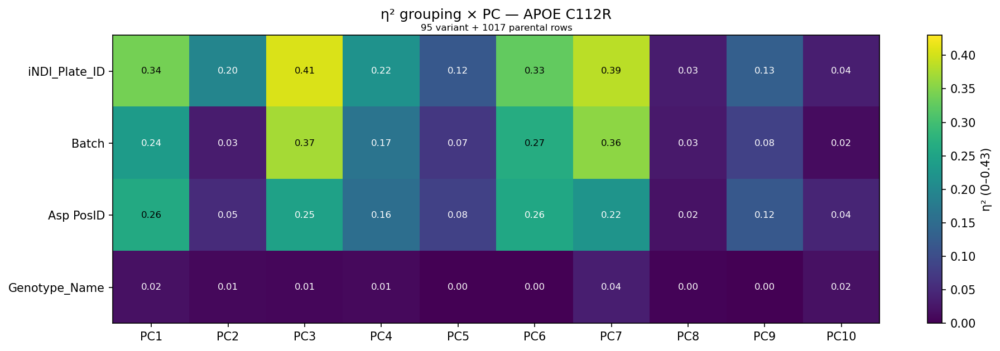

  APOE / R158C: 94 variant + 1017 parental rows


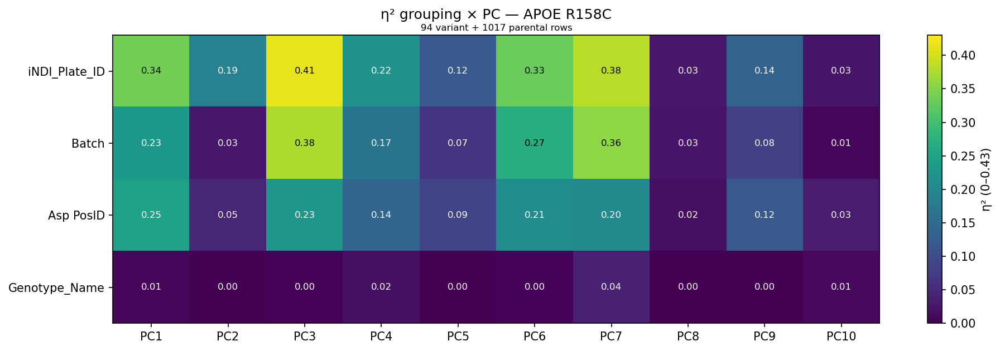

  APP / A673T: 144 variant + 1017 parental rows


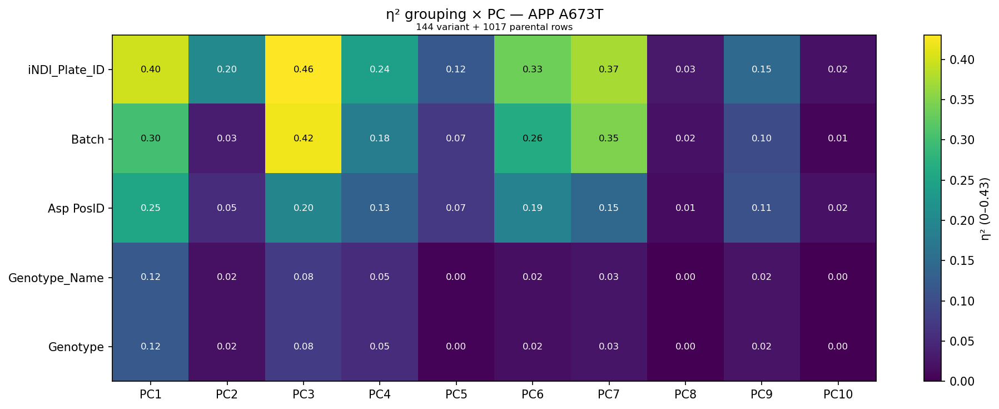

  APP / E693G: 163 variant + 1017 parental rows


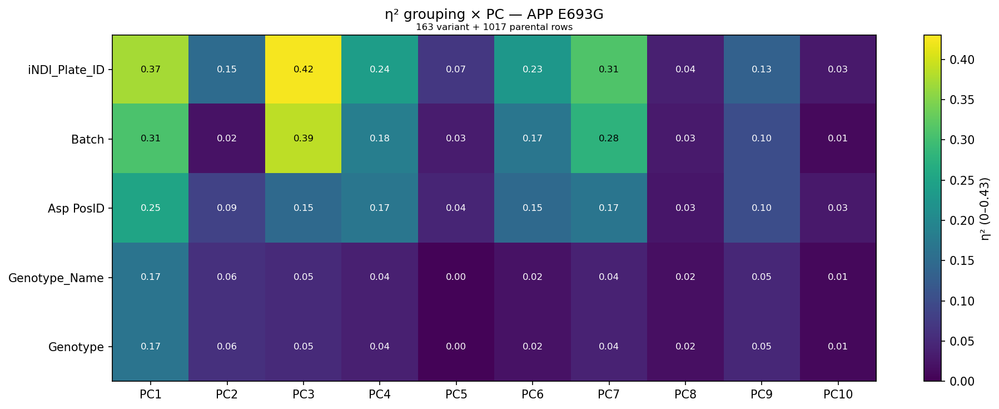

  APP / V717I: 144 variant + 1017 parental rows


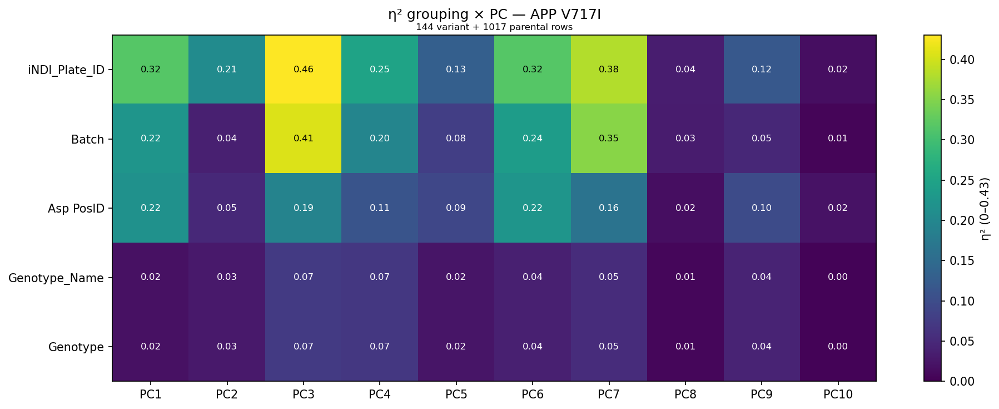

  FUS / R216C: 96 variant + 1017 parental rows


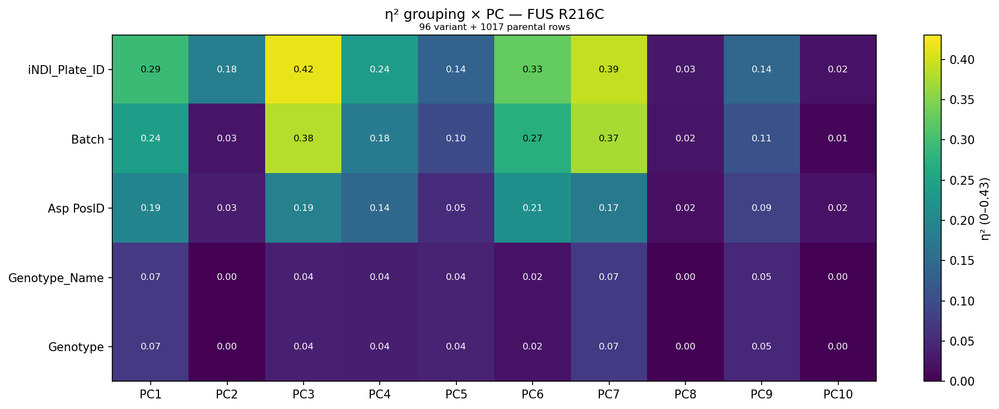

  FUS / R495X: 144 variant + 1017 parental rows


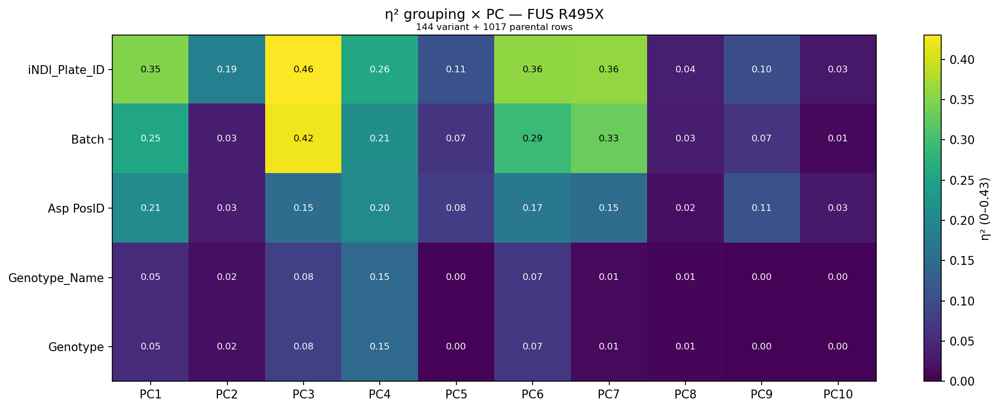

  GRN / Q125X: 125 variant + 1017 parental rows


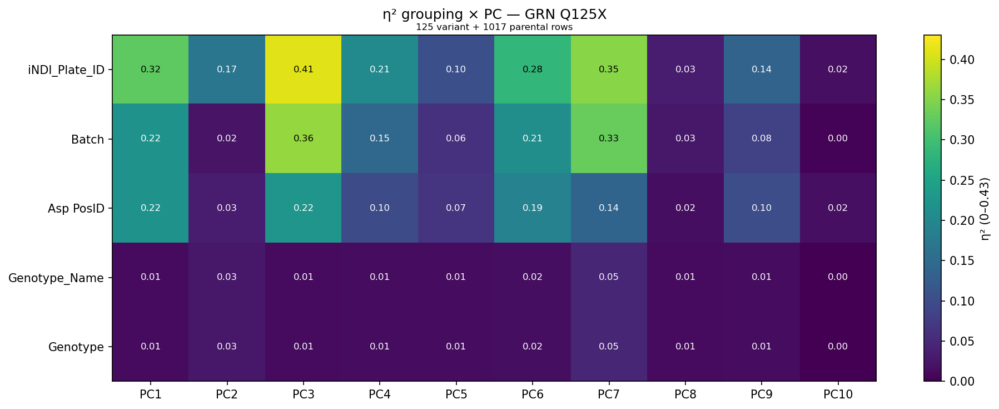

  HNRNPA1 / D262N: 234 variant + 1017 parental rows


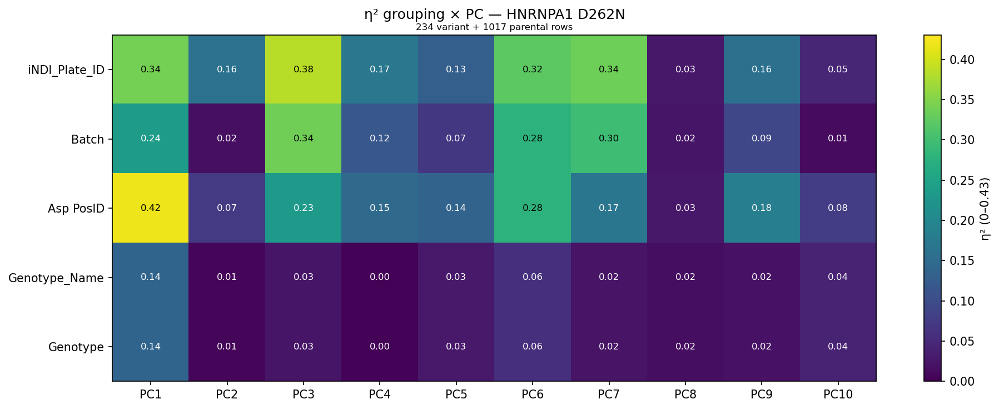

  MAPT / R406W: 143 variant + 1017 parental rows


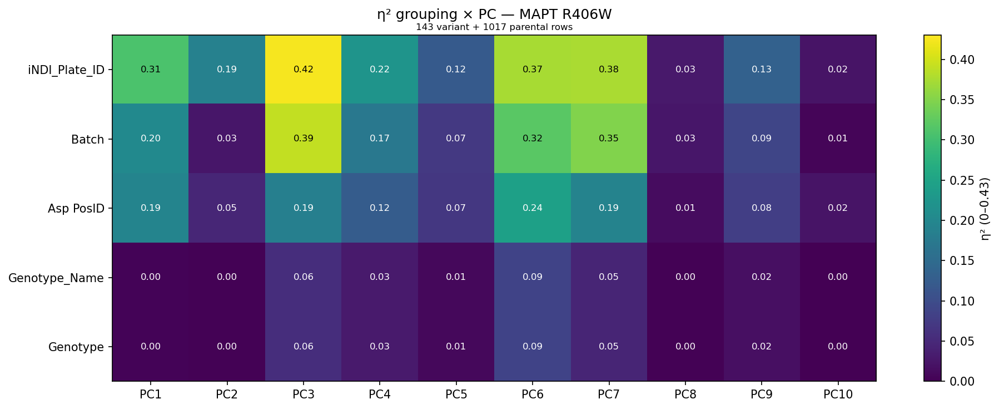

  PFN1 / C71G: 141 variant + 1017 parental rows


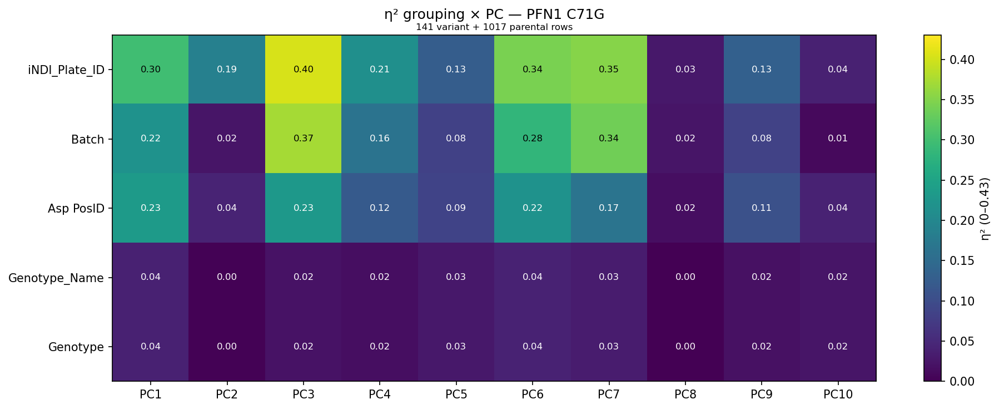

  PSEN1 / E276A: 142 variant + 1017 parental rows


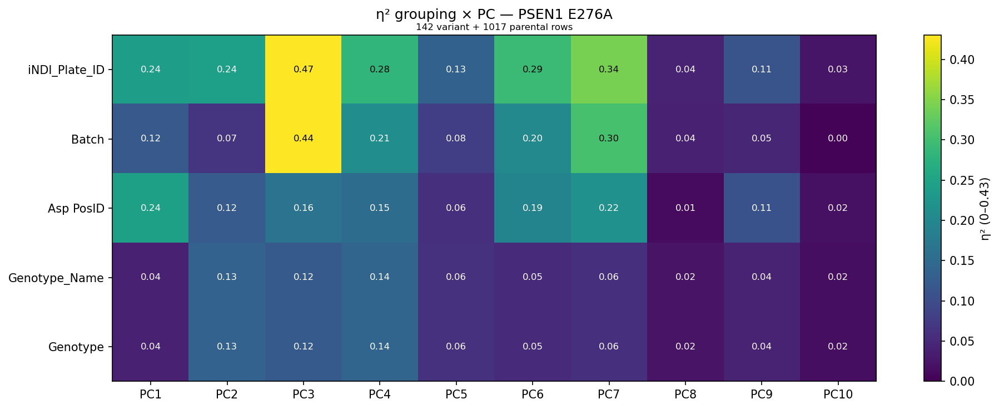

  PSEN2 / N141I: 78 variant + 1017 parental rows


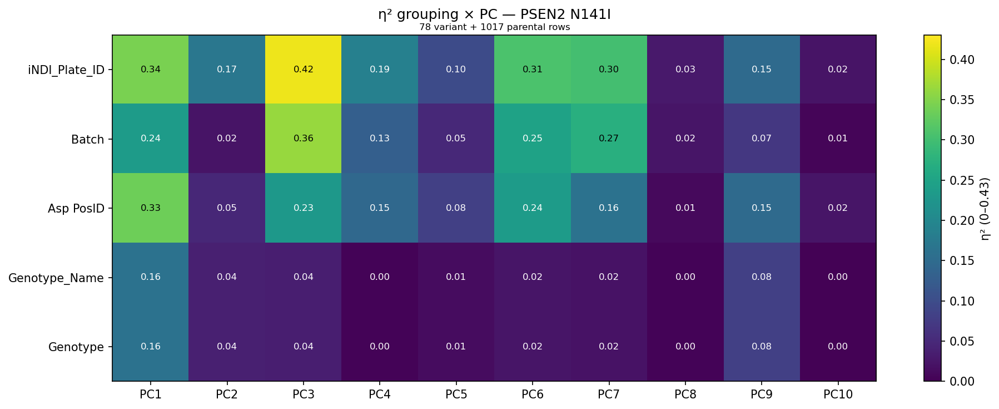

  SNCA / A53T: 94 variant + 1017 parental rows


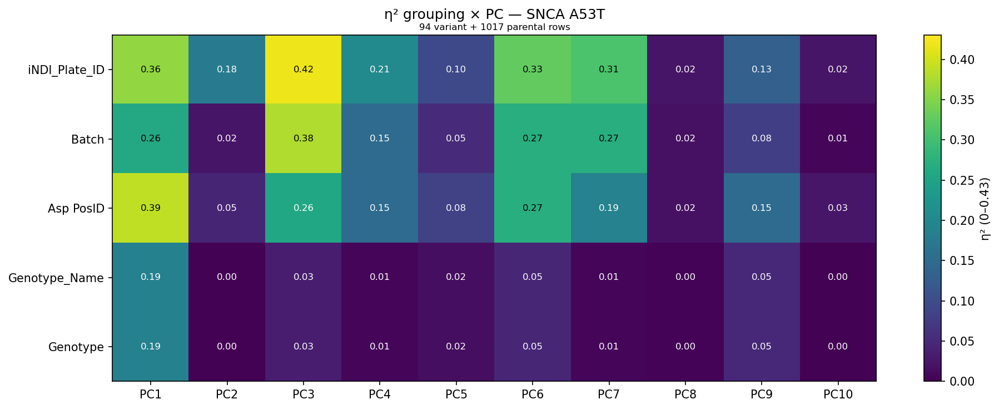

  SNCA / E46K: 42 variant + 1017 parental rows


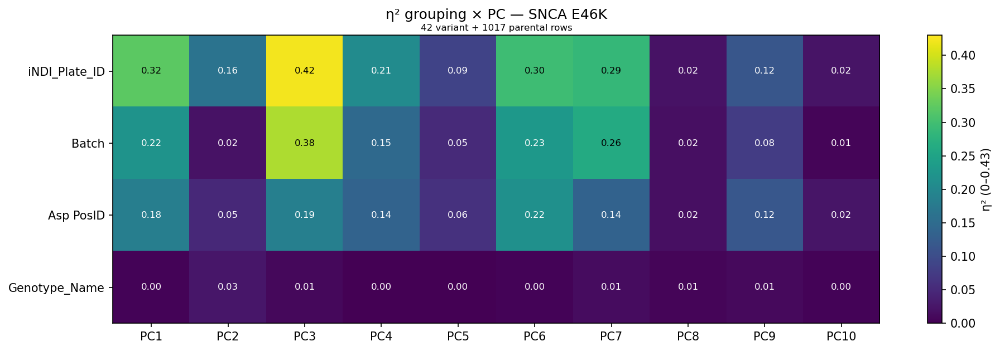

  SNCB / P123H: 117 variant + 1017 parental rows


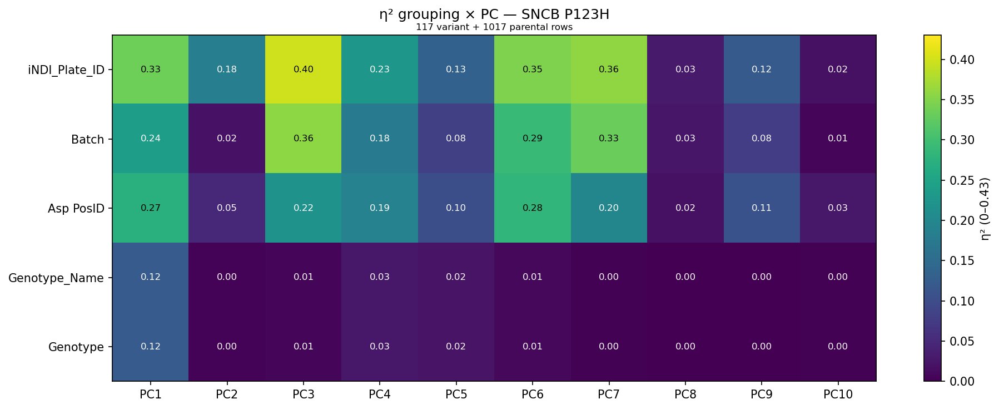

  TARDBP / M337V: 143 variant + 1017 parental rows


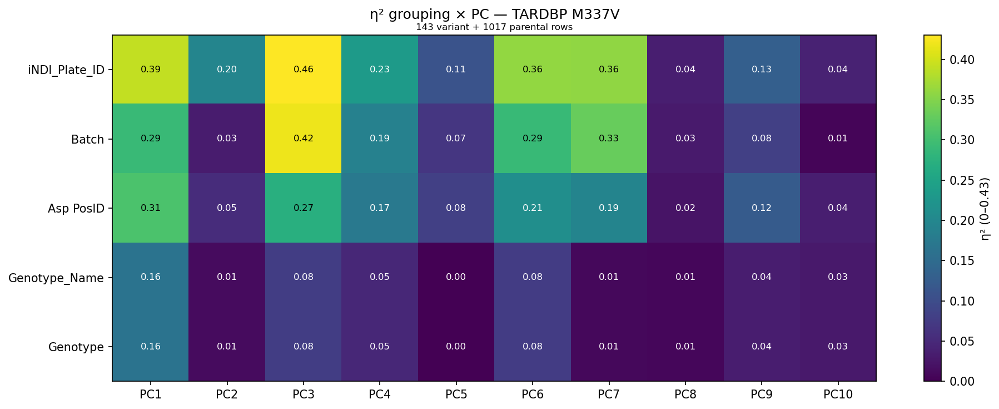

  TARDBP / Q331K: 143 variant + 1017 parental rows


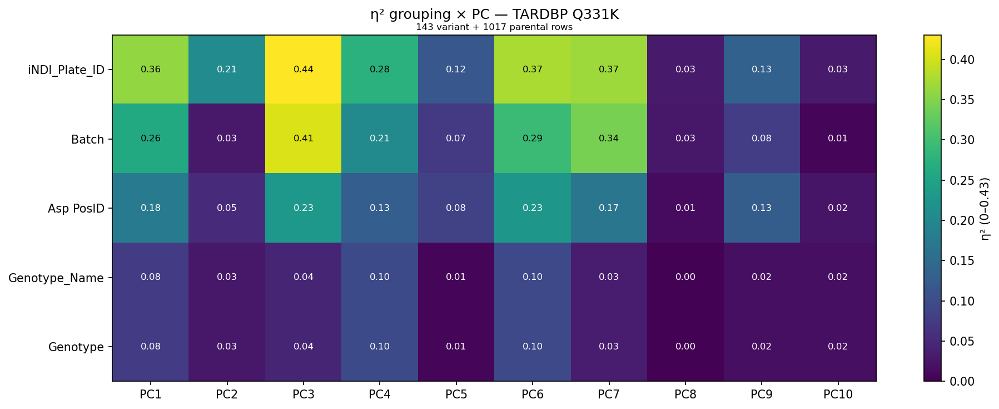

  TBK1 / E696K: 138 variant + 1017 parental rows


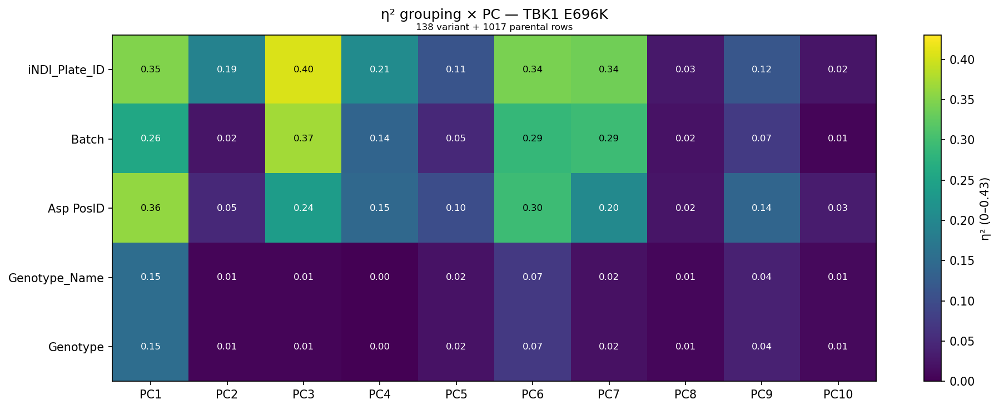

  TIA1 / P351L: 144 variant + 1017 parental rows


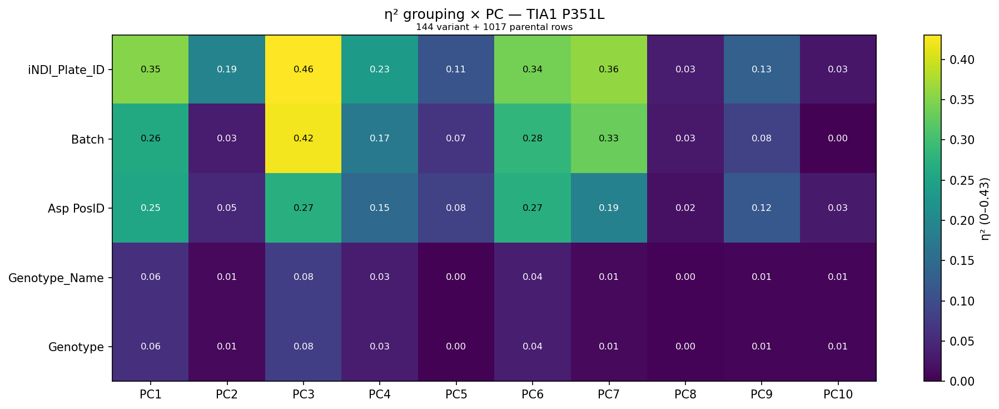

  UBQLN2 / P506T: 48 variant + 1017 parental rows


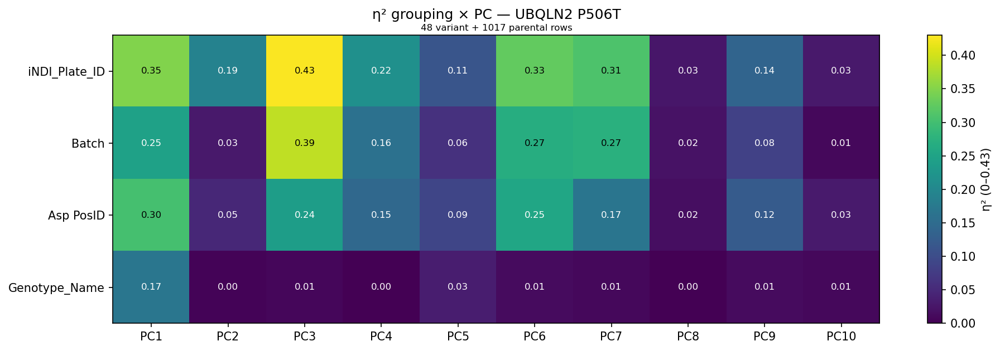

  VCP / R159H: 142 variant + 1017 parental rows


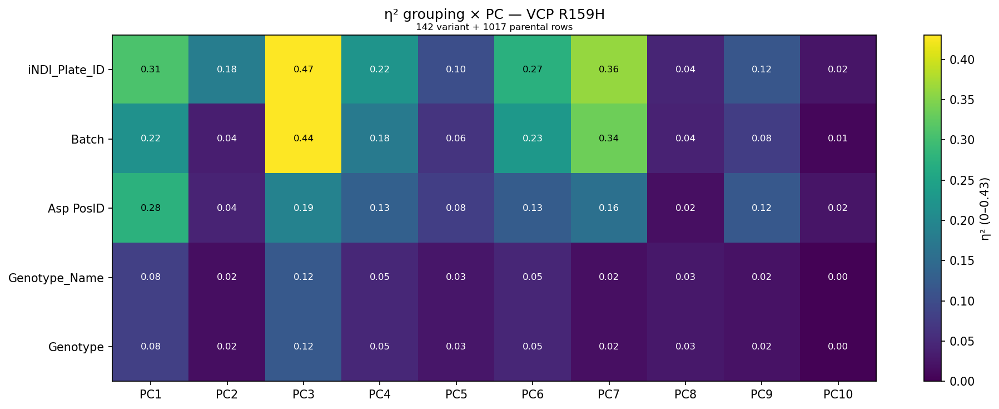

[facet] 22 (gene, variant) pairs; 1017 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 95 variant + 96 parental rows on 1 plate(s)


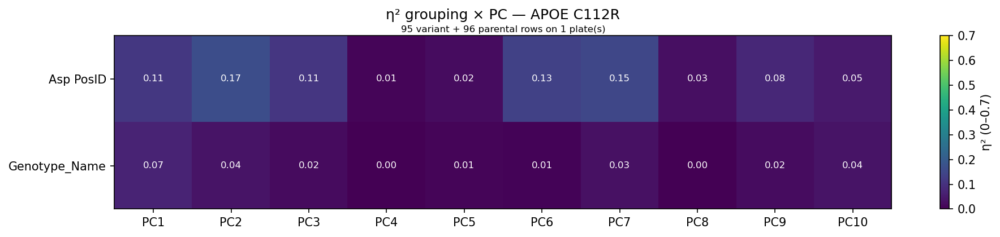

  APOE / R158C: 94 variant + 142 parental rows on 2 plate(s)


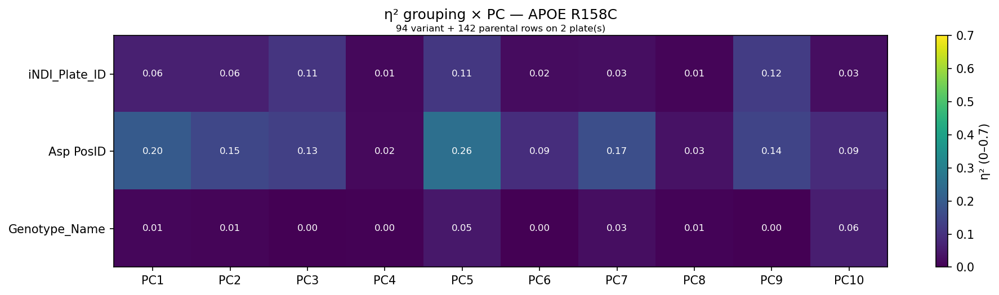

  APP / A673T: 144 variant + 144 parental rows on 2 plate(s)


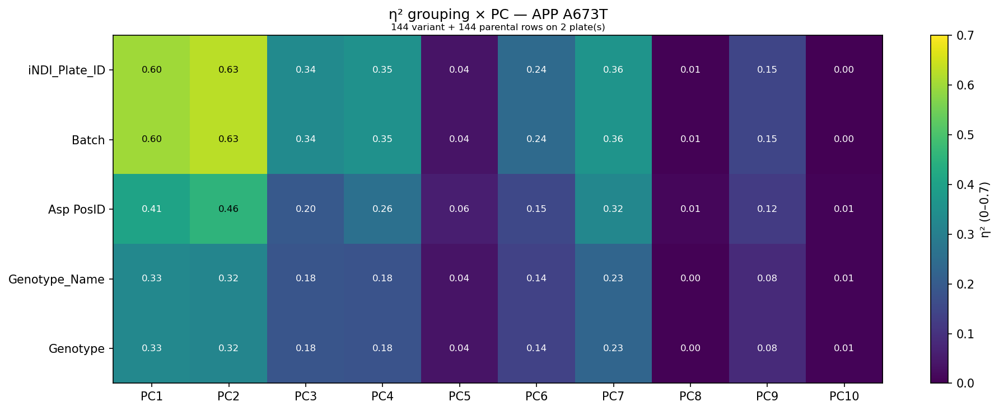

  APP / E693G: 163 variant + 240 parental rows on 3 plate(s)


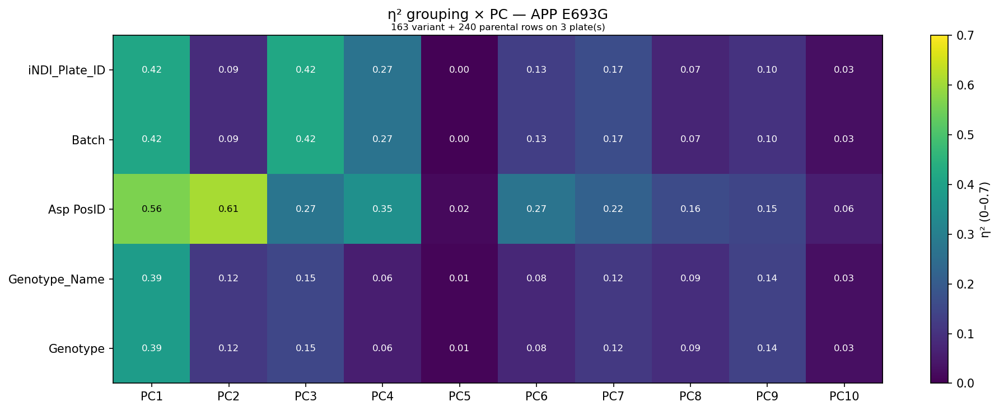

  APP / V717I: 144 variant + 144 parental rows on 2 plate(s)


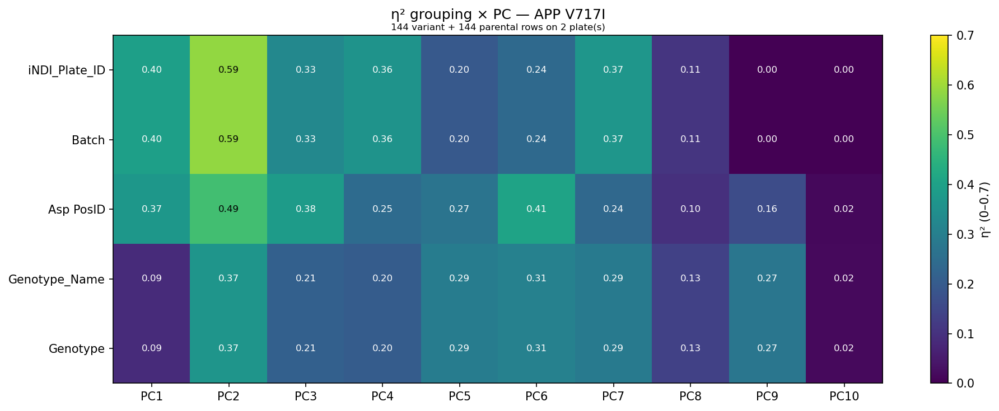

  FUS / R216C: 96 variant + 96 parental rows on 1 plate(s)


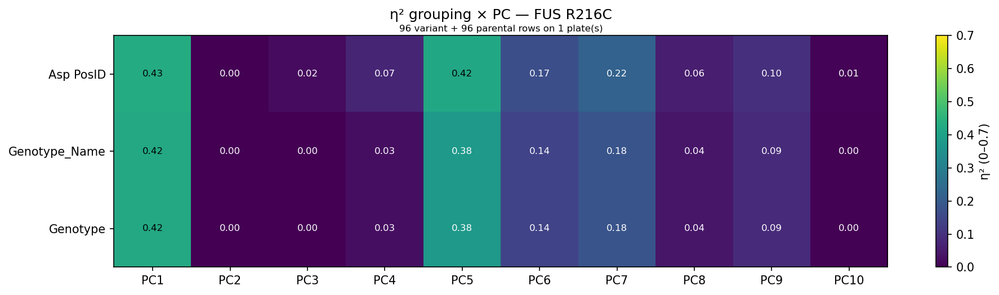

  FUS / R495X: 144 variant + 95 parental rows on 1 plate(s)


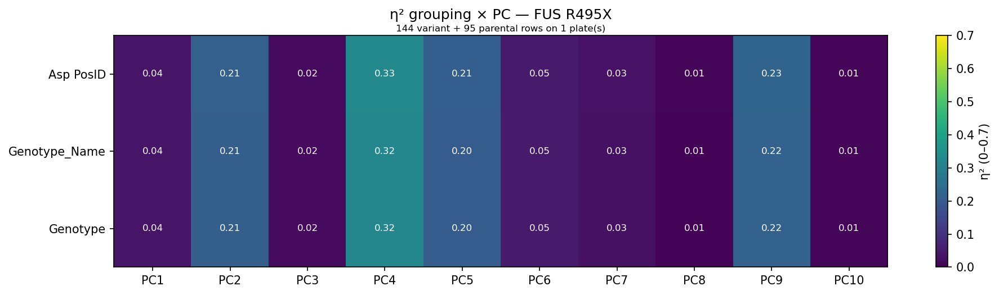

  GRN / Q125X: 125 variant + 112 parental rows on 2 plate(s)


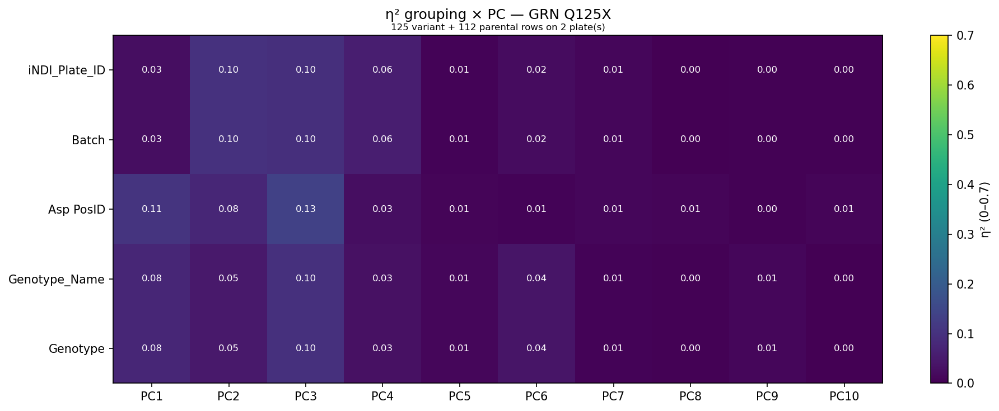

  HNRNPA1 / D262N: 234 variant + 233 parental rows on 3 plate(s)


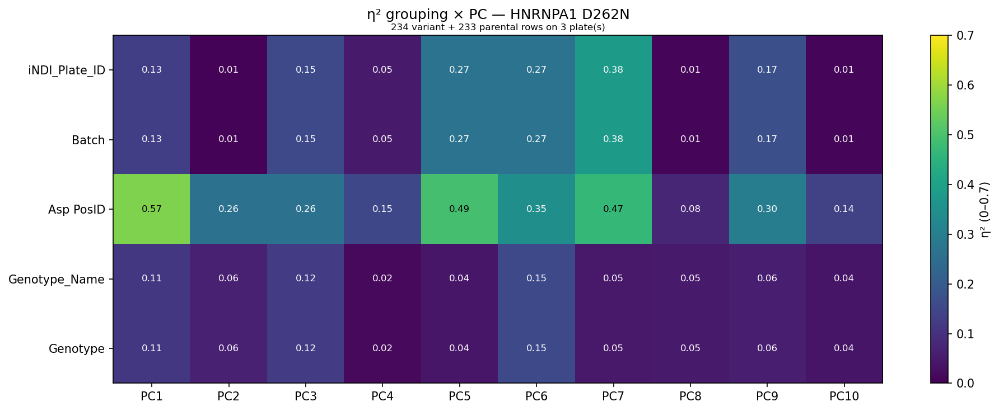

  MAPT / R406W: 143 variant + 96 parental rows on 1 plate(s)


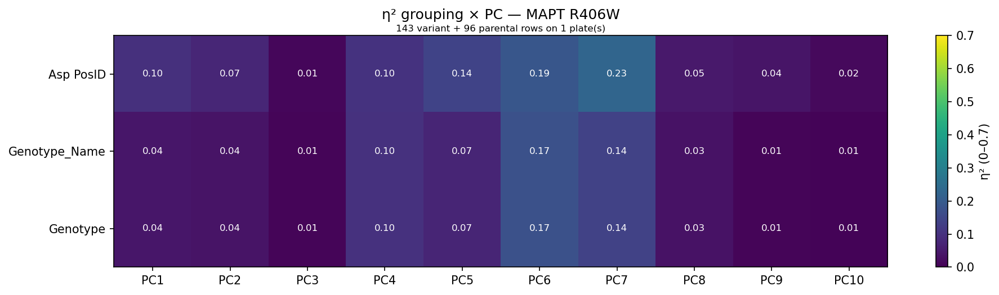

  PFN1 / C71G: 141 variant + 137 parental rows on 2 plate(s)


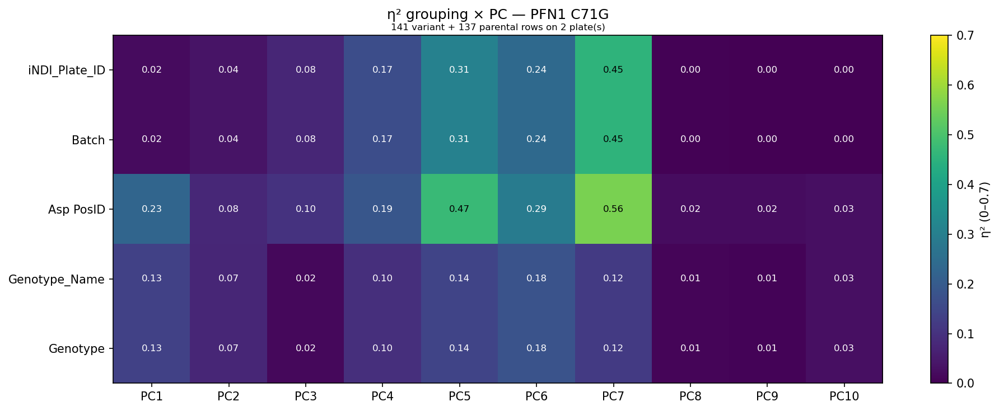

  PSEN1 / E276A: 142 variant + 240 parental rows on 3 plate(s)


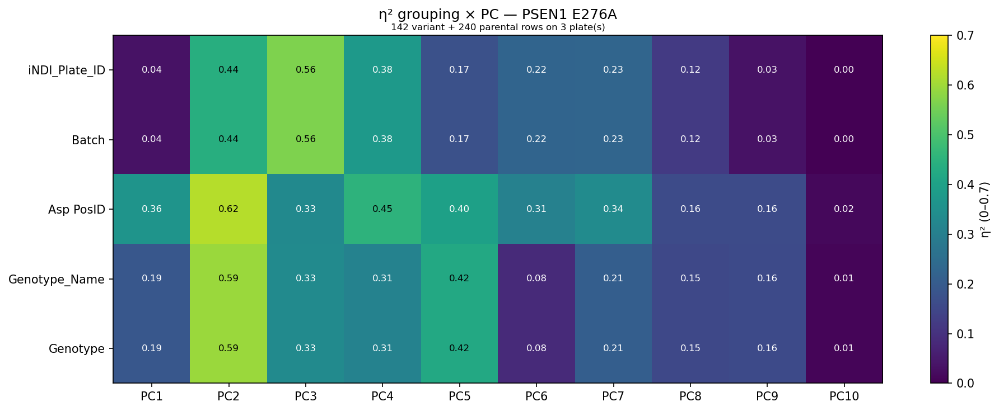

  PSEN2 / N141I: 78 variant + 162 parental rows on 2 plate(s)


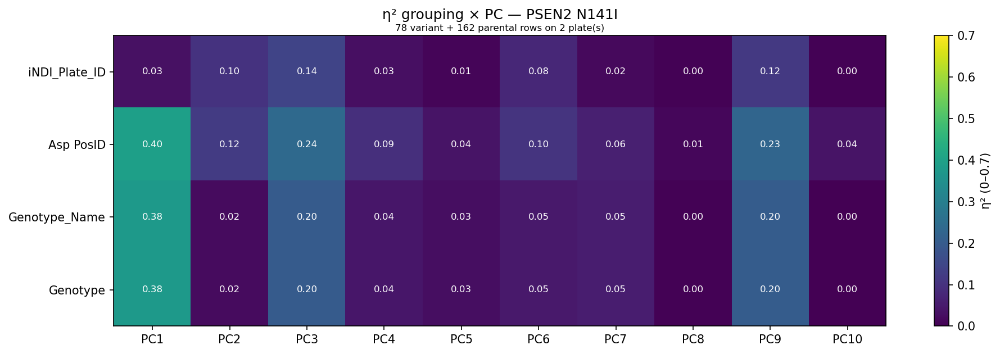

  SNCA / A53T: 94 variant + 96 parental rows on 1 plate(s)


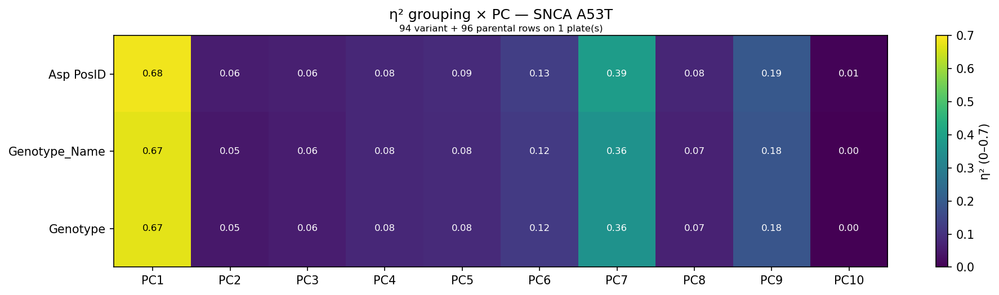

  SNCA / E46K: 42 variant + 66 parental rows on 1 plate(s)


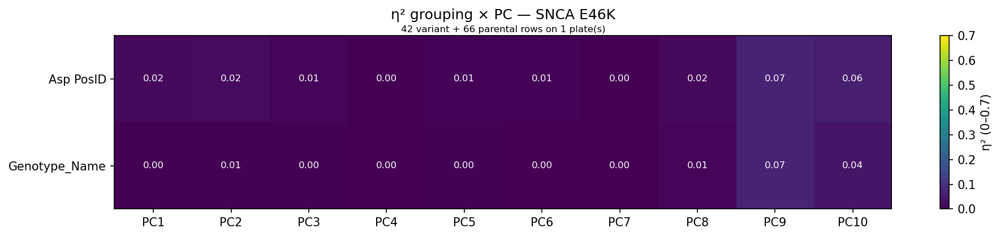

  SNCB / P123H: 117 variant + 192 parental rows on 2 plate(s)


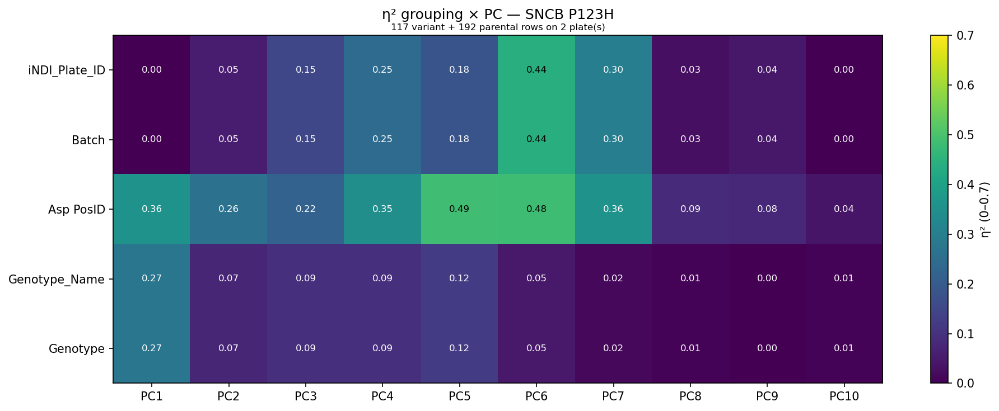

  TARDBP / M337V: 143 variant + 191 parental rows on 2 plate(s)


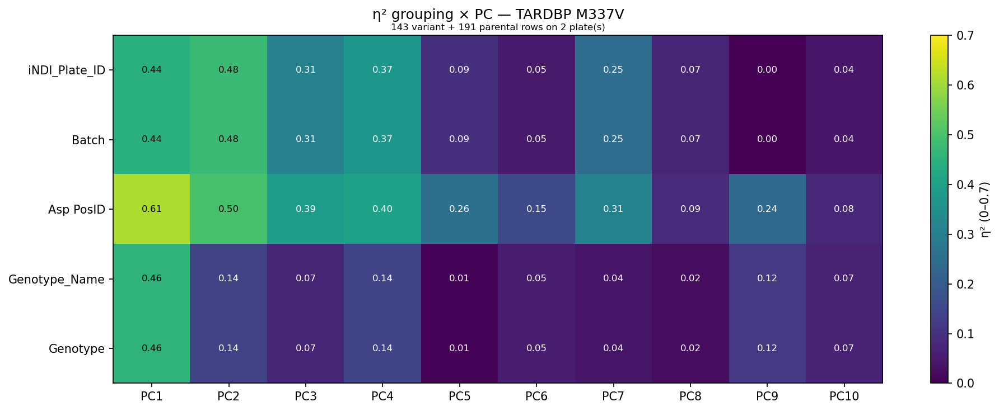

  TARDBP / Q331K: 143 variant + 191 parental rows on 2 plate(s)


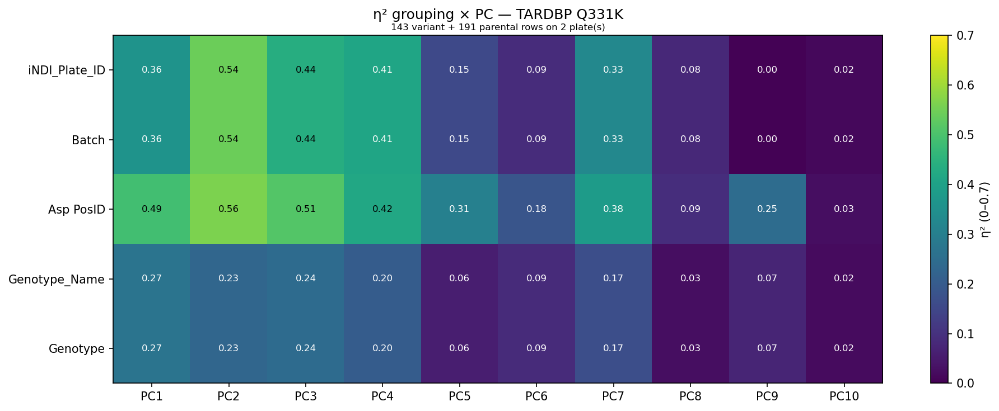

  TBK1 / E696K: 138 variant + 96 parental rows on 1 plate(s)


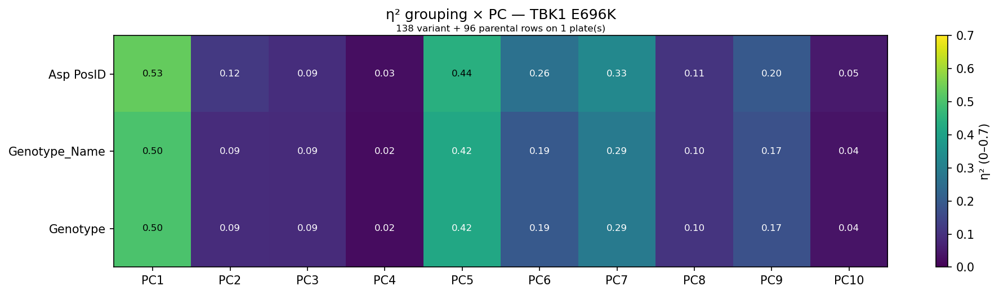

  TIA1 / P351L: 144 variant + 191 parental rows on 2 plate(s)


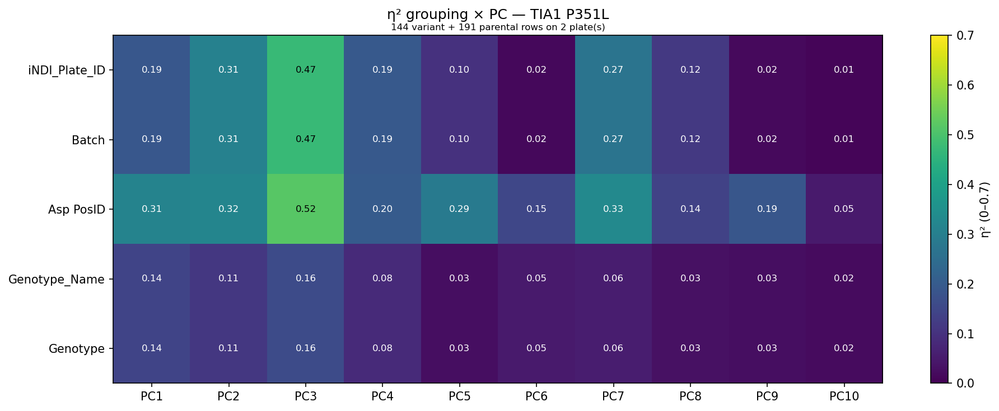

  UBQLN2 / P506T: 48 variant + 96 parental rows on 1 plate(s)


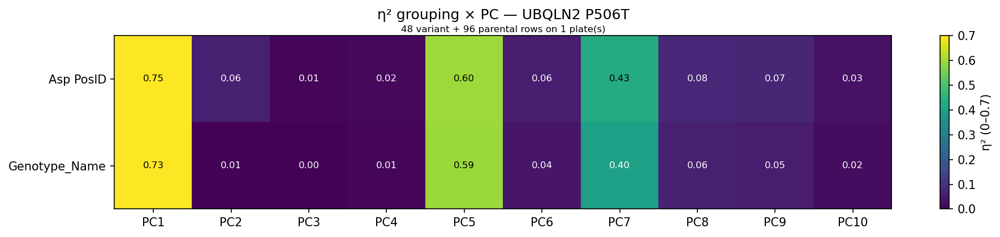

  VCP / R159H: 142 variant + 95 parental rows on 1 plate(s)


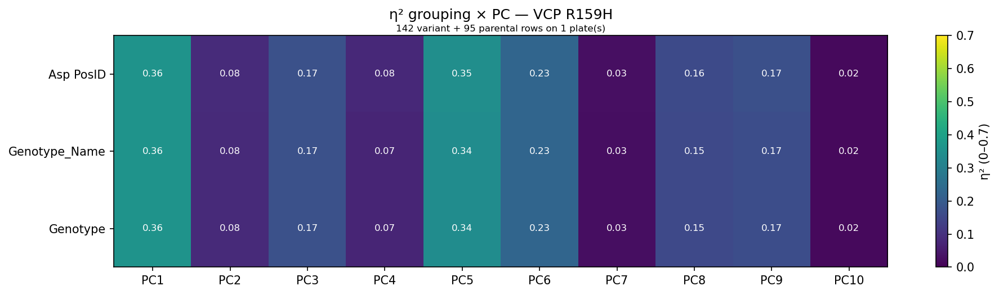

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["iNDI_Plate_ID", "Batch", "Asp PosID", "Genotype_Name", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

### Genotype faceted PCAs


AUTOMATED (3930 wells)


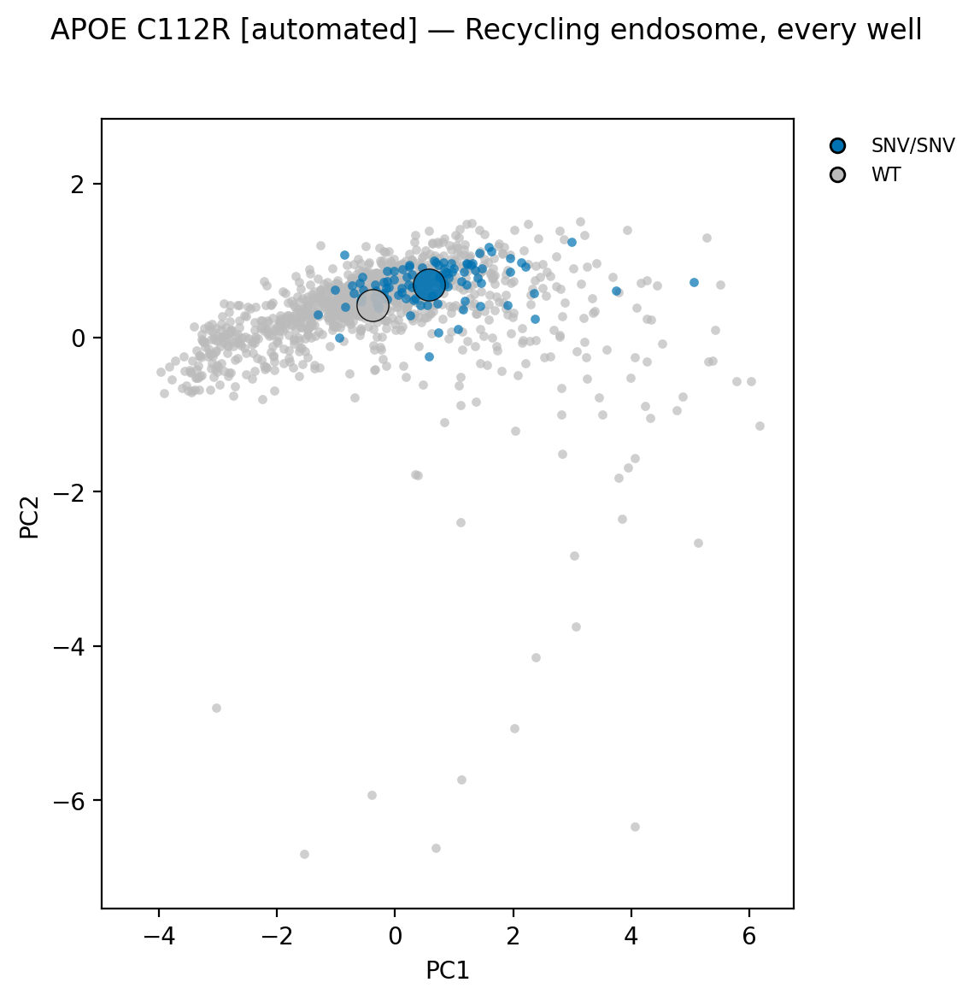

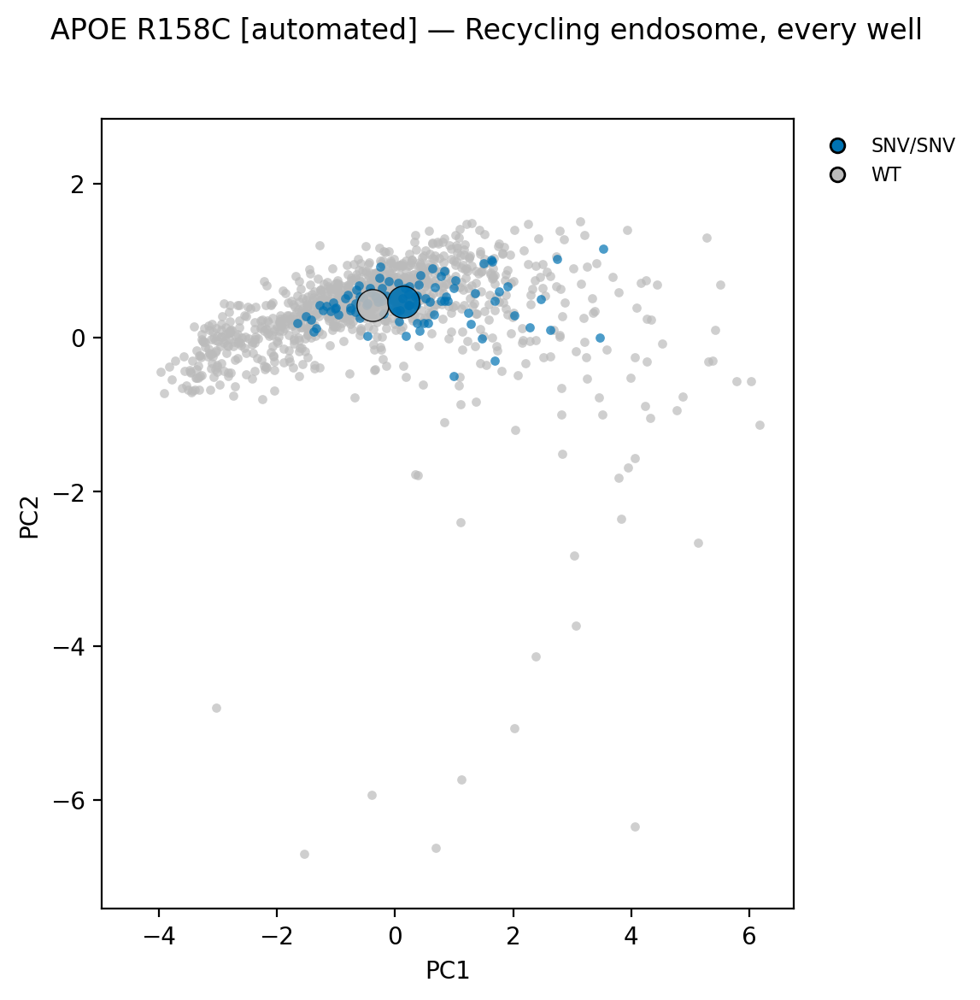

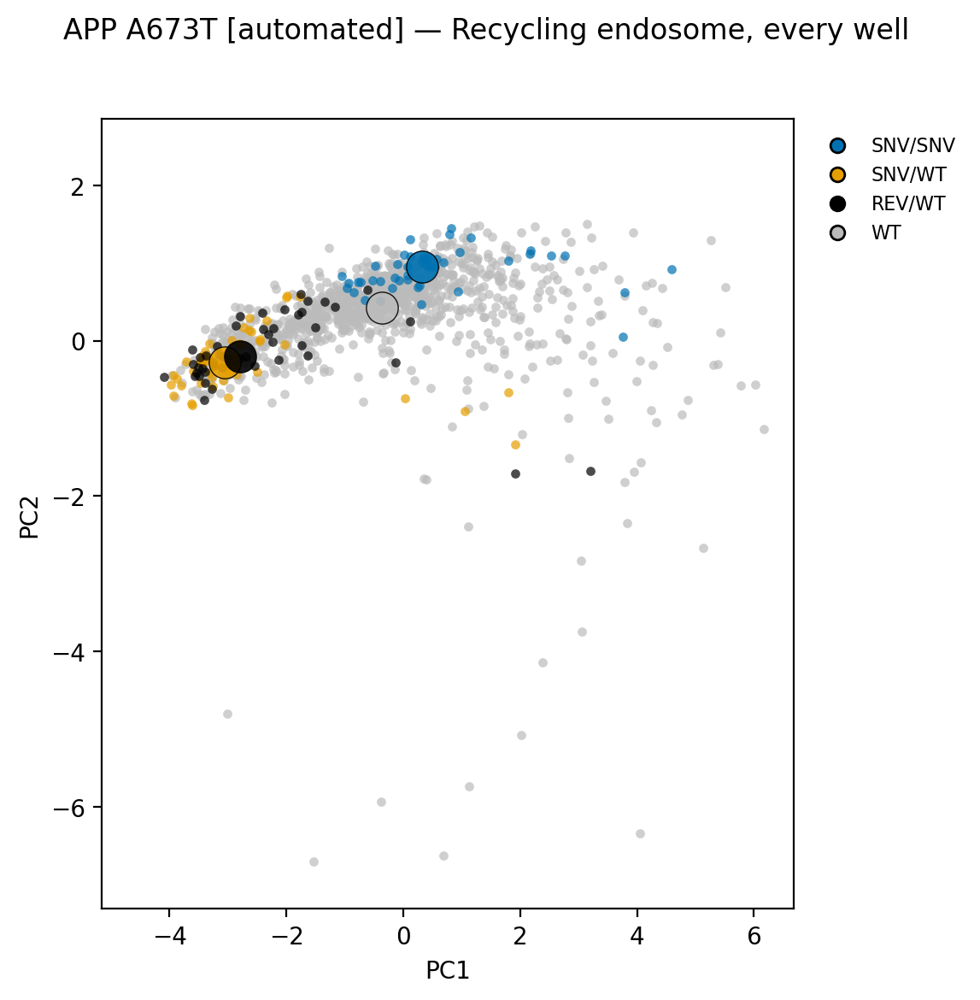

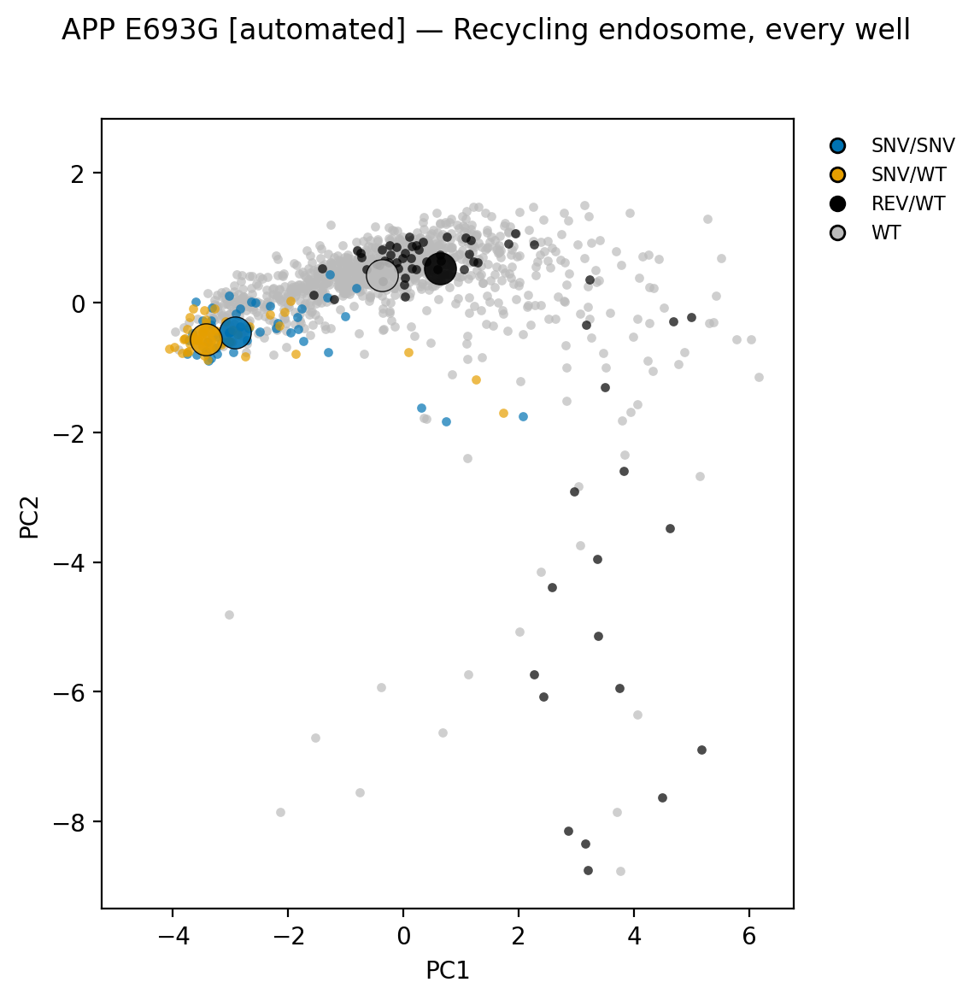

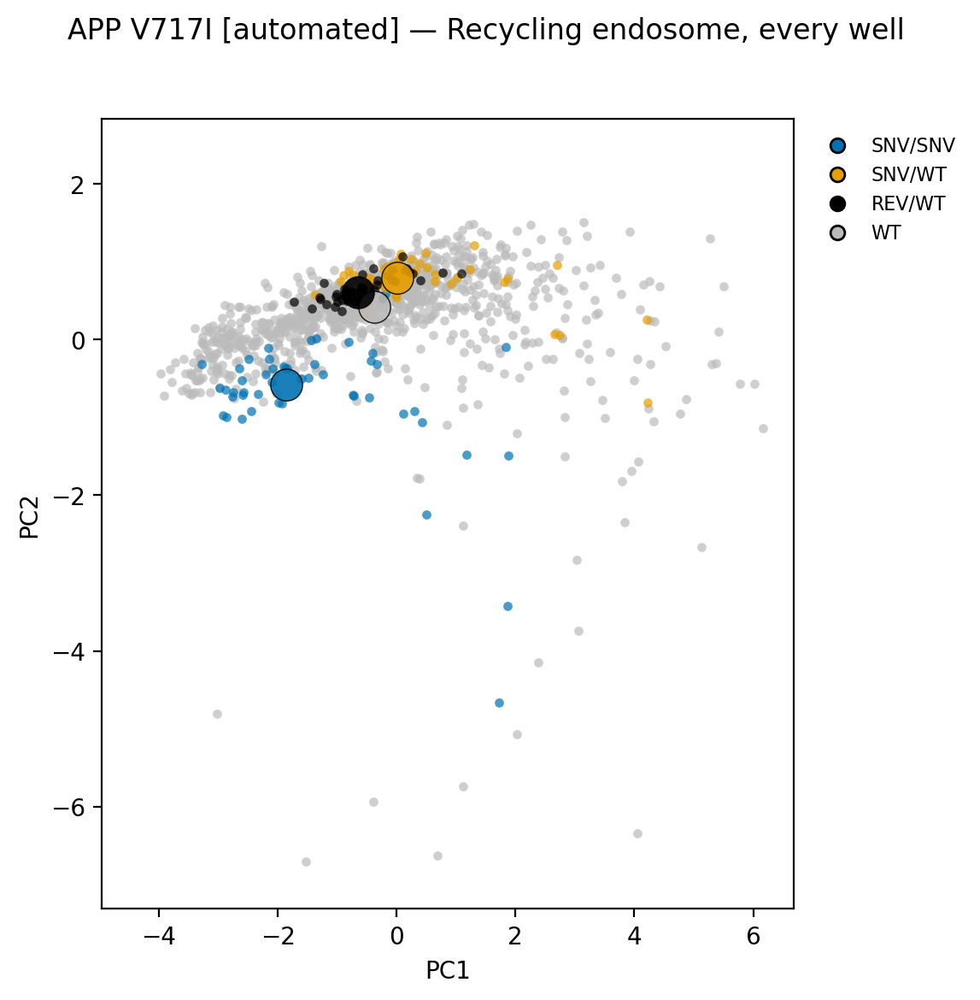

...

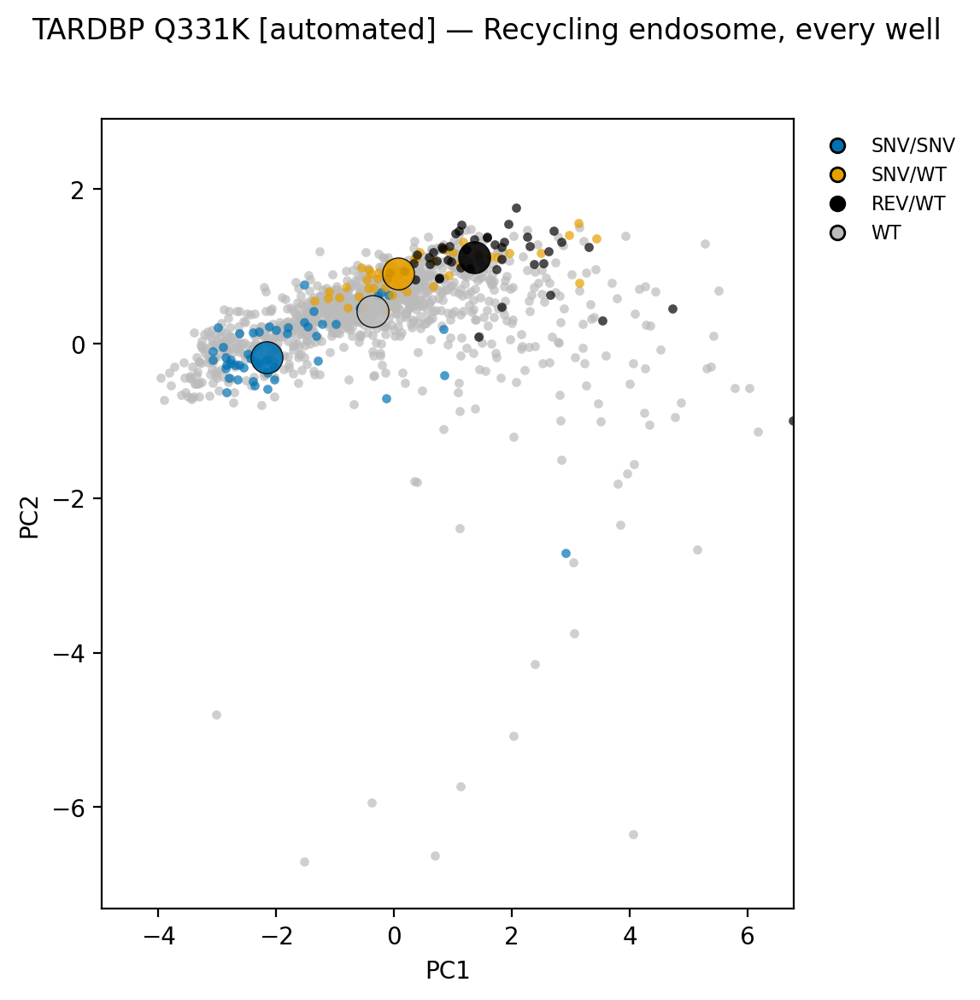

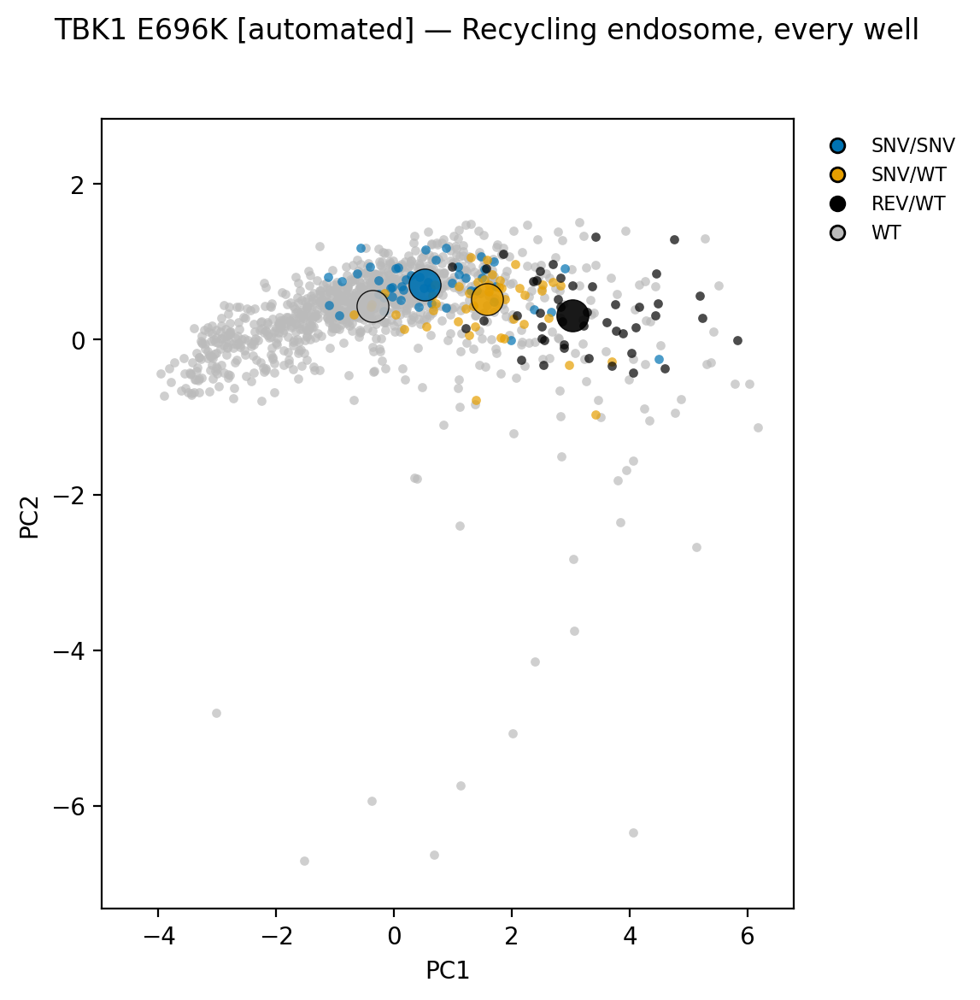

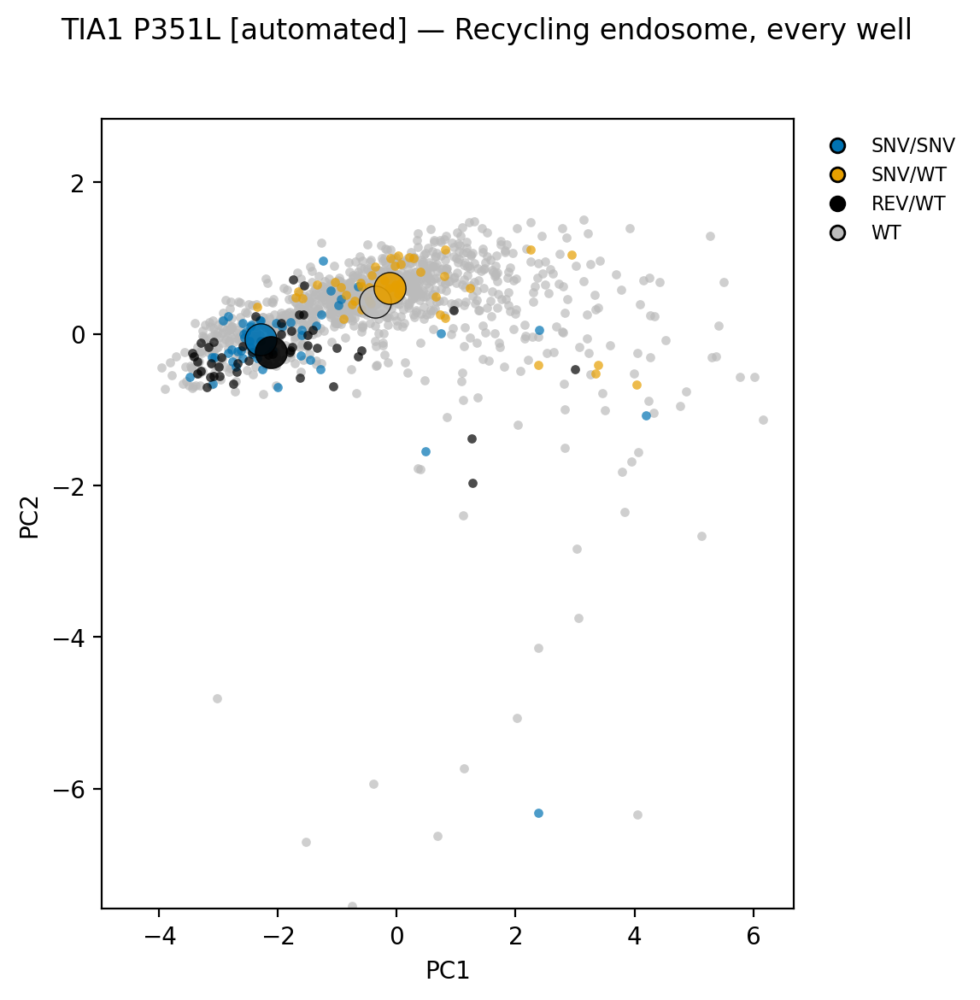

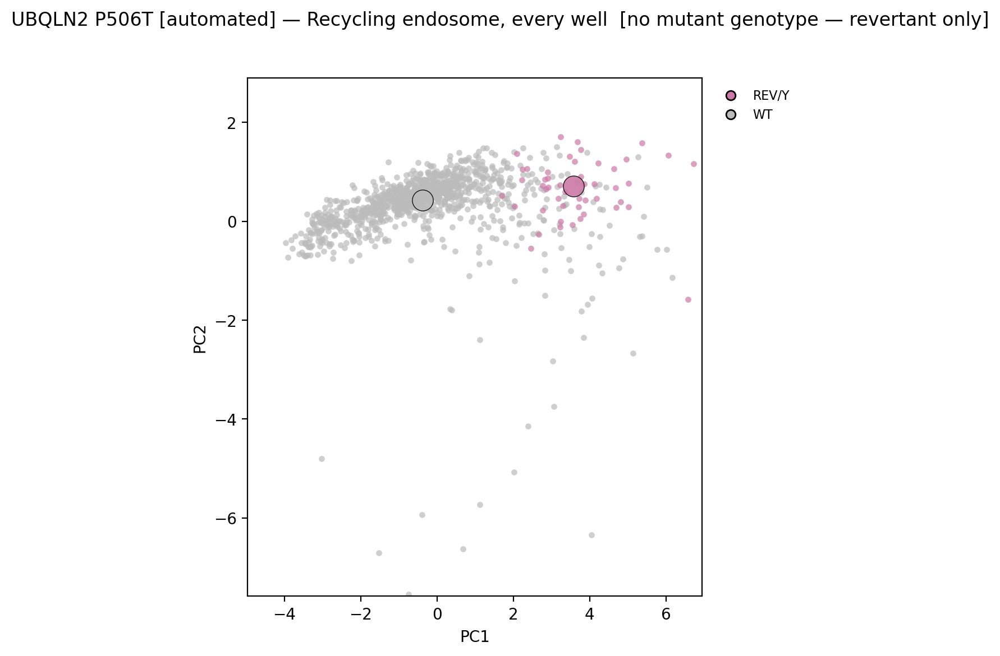

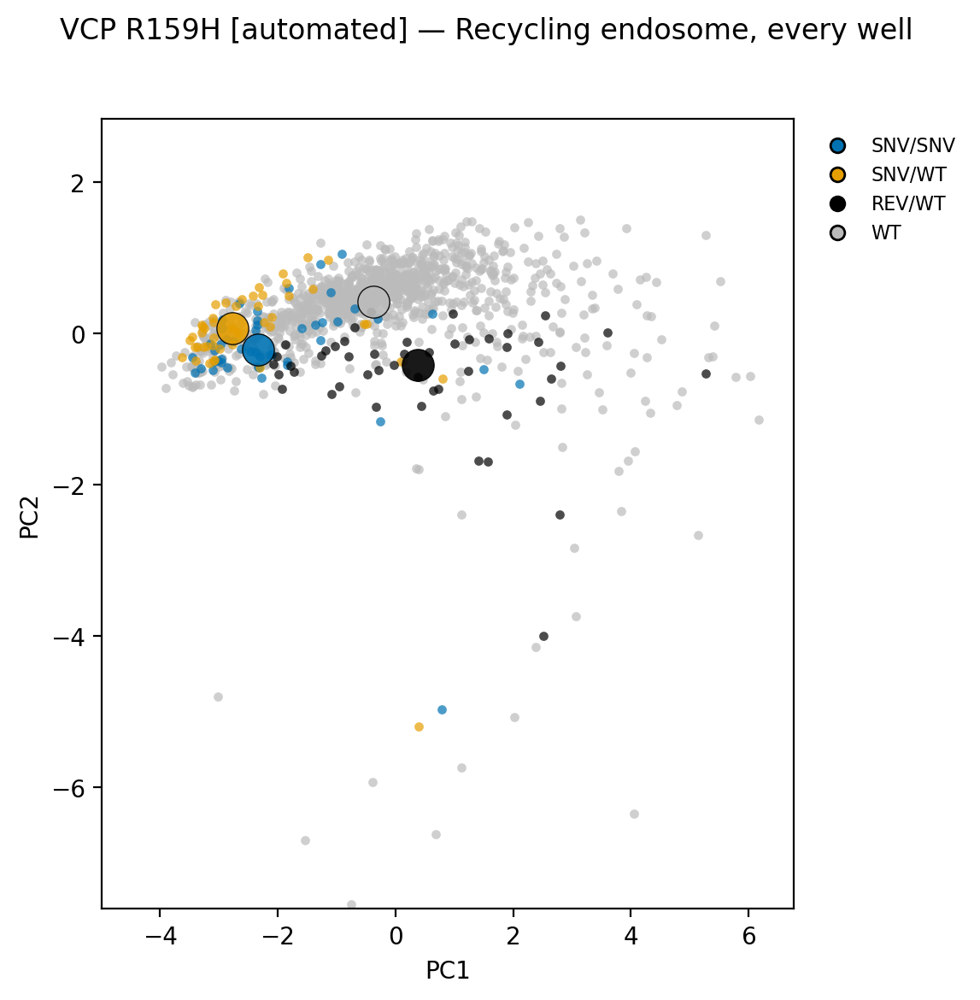

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — Recycling endosome, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)

run_group(well_level, SCHEMES["automated"])

# Parental-only analysis

In [14]:
# filter for parentals
parental = df[df["Gene"] == "KOLF2.1J"]

## ROI level analysis
### Feature assessment and PCA loadings


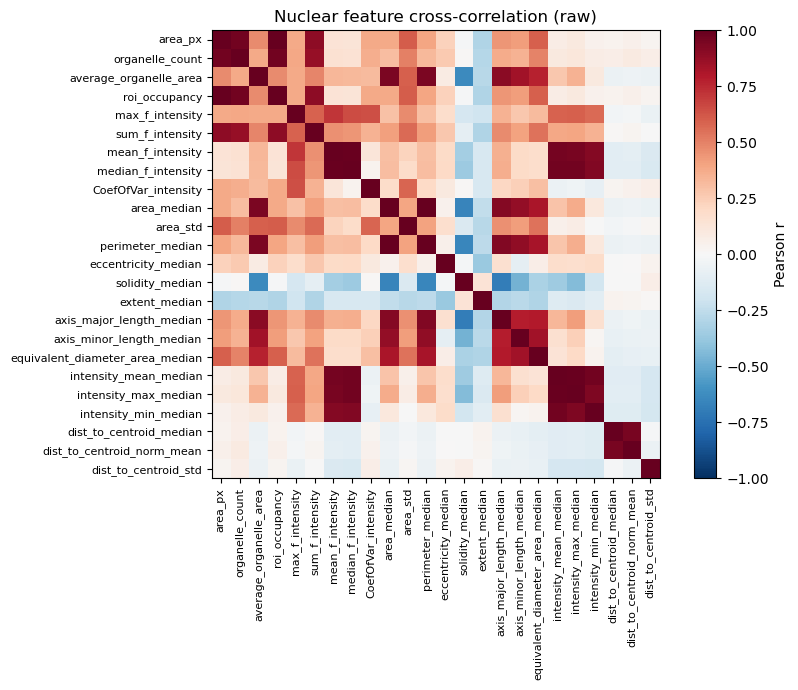

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.992  area_median            perimeter_median
  +0.989  mean_f_intensity       median_f_intensity
  +0.989  intensity_mean_median  intensity_max_median
  +0.967  median_f_intensity     intensity_mean_median
  +0.967  intensity_mean_median  intensity_min_median
  +0.963  area_px                organelle_count
  +0.963  organelle_count        roi_occupancy
  +0.962  median_f_intensity     intensity_max_median
  +0.956  mean_f_intensity       intensity_mean_median
  +0.952  mean_f_intensity       intensity_max_median
  +0.952  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.945  average_organelle_area area_median
  +0.944  average_organelle_area perimeter_median
  +0.932  intensity_max_median   intensity_min_median
  +0.925  perimeter_median       axis_major_length_median
  +0.923  median_f_intensity     intensity_min_median
  +0.918  mean_f_intensity       intensity_min_median
  +0.916  area_m

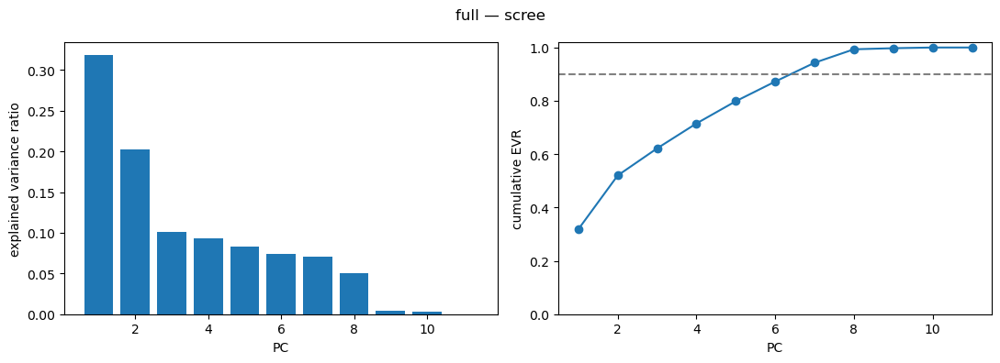

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.498 -0.173 -0.141 -0.081 -0.072 -0.160 -0.056   
organelle_count             0.495 -0.171 -0.122 -0.065 -0.037 -0.179  0.023   
roi_occupancy               0.498 -0.173 -0.141 -0.081 -0.072 -0.160 -0.056   
mean_f_intensity            0.209  0.563 -0.072 -0.126  0.029  0.093  0.325   
CoefOfVar_intensity         0.254 -0.123 -0.040 -0.139  0.238  0.899  0.038   
eccentricity_median         0.221  0.087  0.580  0.388 -0.067 -0.050  0.344   
solidity_median            -0.075 -0.393  0.101 -0.037 -0.433  0.108  0.662   
extent_median              -0.253 -0.080 -0.499 -0.355  0.056 -0.139  0.423   
intensity_max_median        0.177  0.600 -0.084 -0.099  0.023 -0.074  0.227   
dist_to_centroid_norm_mean  0.024 -0.122 -0.387  0.688  0.511 -0.055  0.261   
dist_to_centroid_std        0.006 -0.189  0.432 -0.431  0.688 -0.240  0.177   

                              PC8    PC9   PC10   P

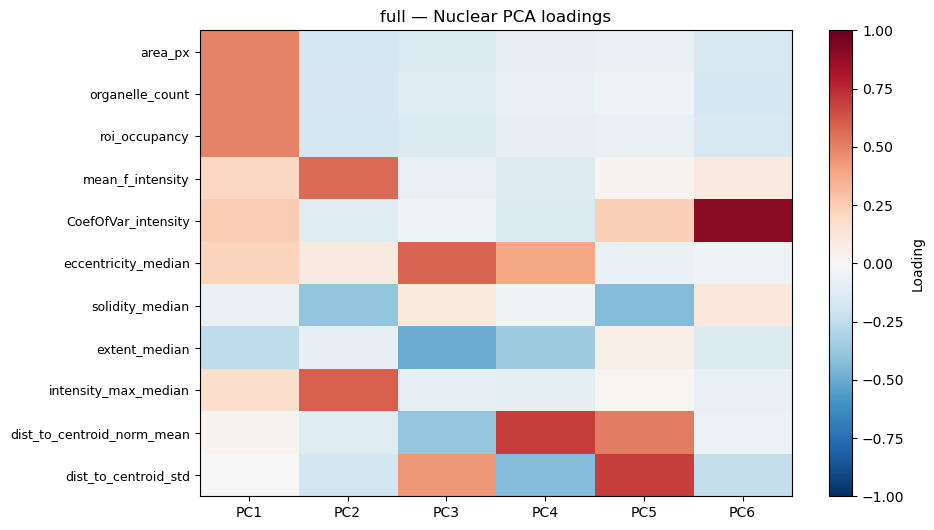

In [15]:
feature_correlation(parental)
parental, pca, FEATURES = fit_pca(parental, label="full")

### PCA plots
#### All parentals


All 12 iNDI_Plate_ID values have a color.


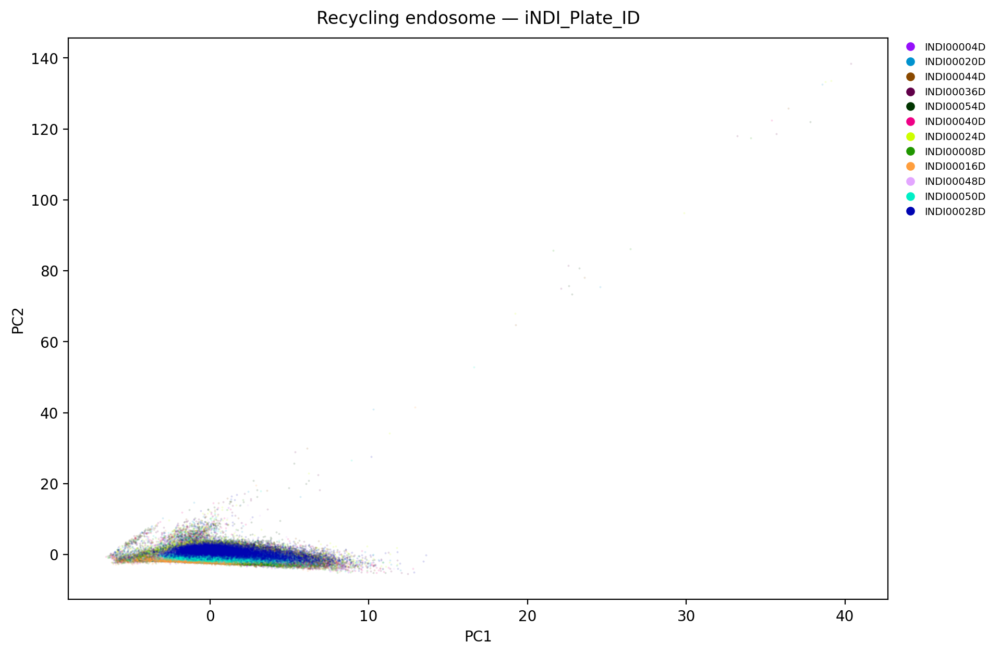

All 4 Batch values have a color.


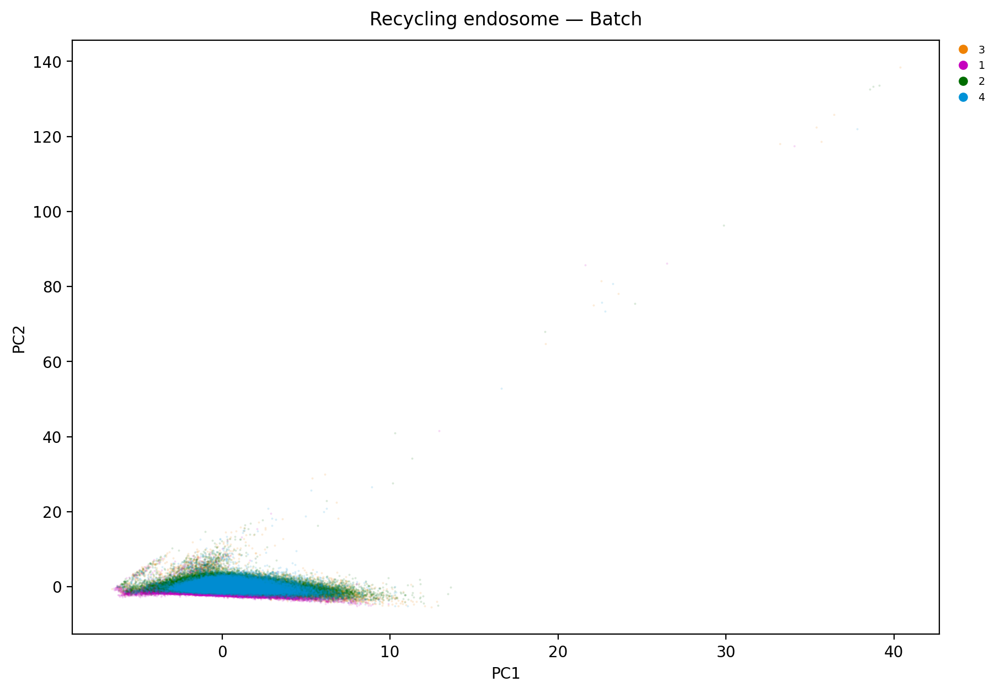

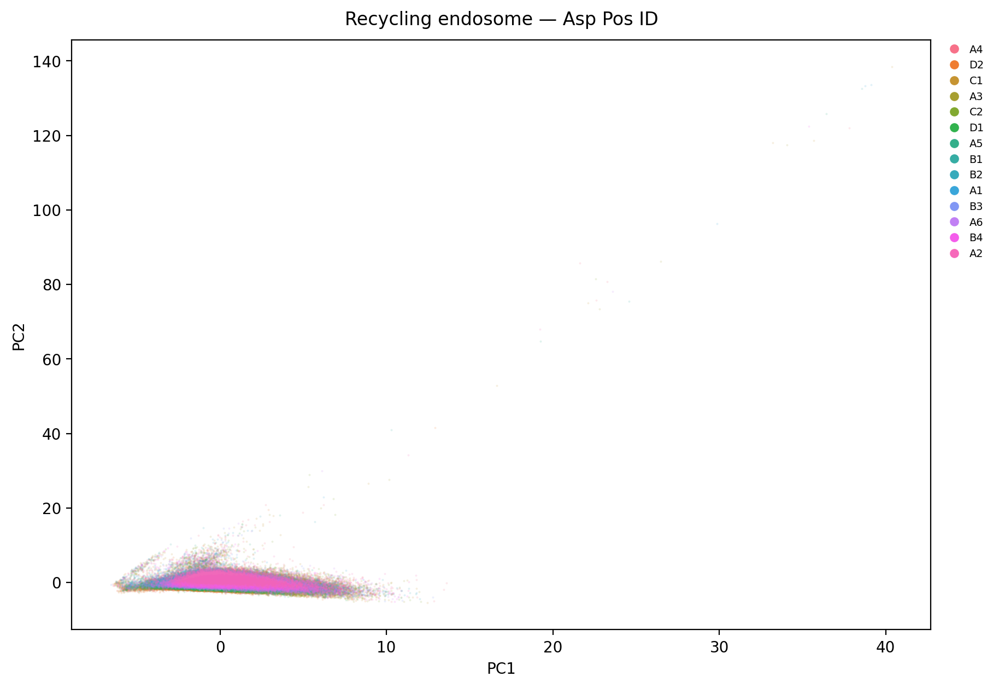

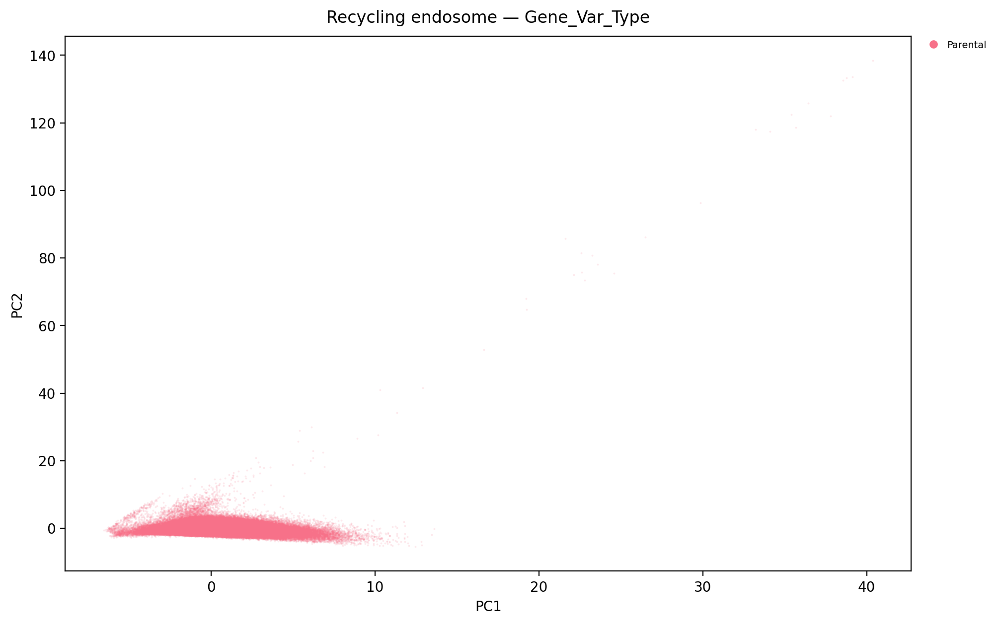

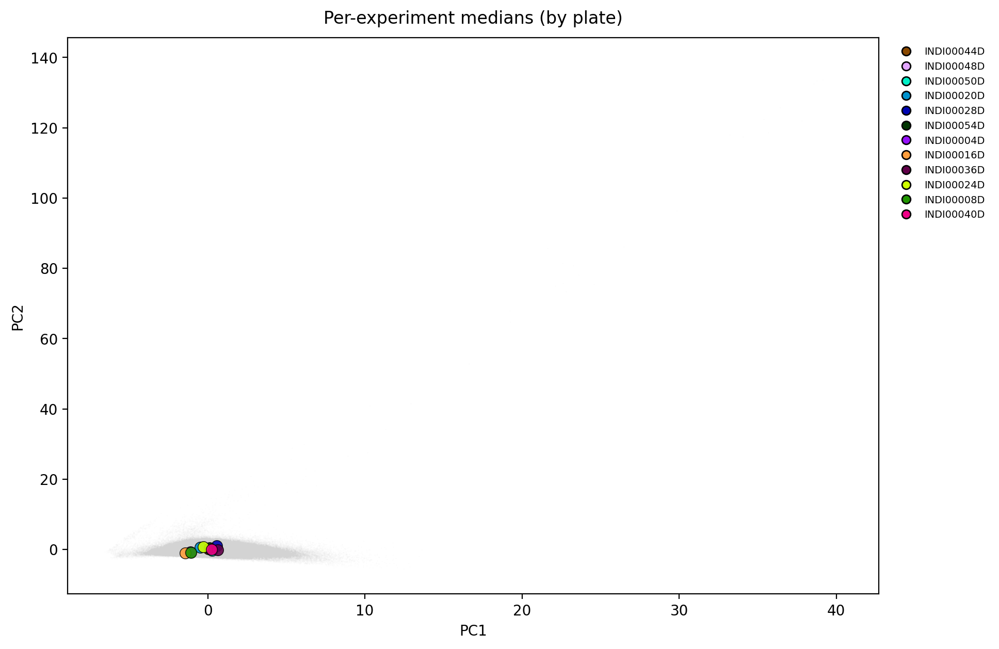

Std of per-experiment centroids (batch magnitude):
PC1    0.684
PC2    0.652
PC3    0.099
dtype: float64


In [16]:
plate_pal = make_palette(parental["iNDI_Plate_ID"])
check_palette_coverage(parental, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Recycling endosome — iNDI_Plate_ID")

batch_palette = make_palette(parental["Batch"])
check_palette_coverage(parental, "Batch", batch_palette)
pca_scatter(parental, "Batch", palette=batch_palette, figsize=(12, 7),title="Recycling endosome — Batch")

pca_scatter(parental, "Asp PosID", figsize=(12, 7),title="Recycling endosome — Asp Pos ID")

pca_scatter(parental, "Genotype_Name", figsize=(13, 7), legend_ncol=2, title="Recycling endosome — Gene_Var_Type")

centroid_overlay(parental, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 56071 rows (22568 images)
[full] well-level: 1017 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 1017 remain
[full well] EVR: [0.401 0.245 0.195 0.06  0.041 0.029 0.021 0.007 0.002 0.    0.   ]
[full well] cumulative: [0.401 0.646 0.841 0.901 0.942 0.97  0.991 0.998 1.    1.    1.   ]


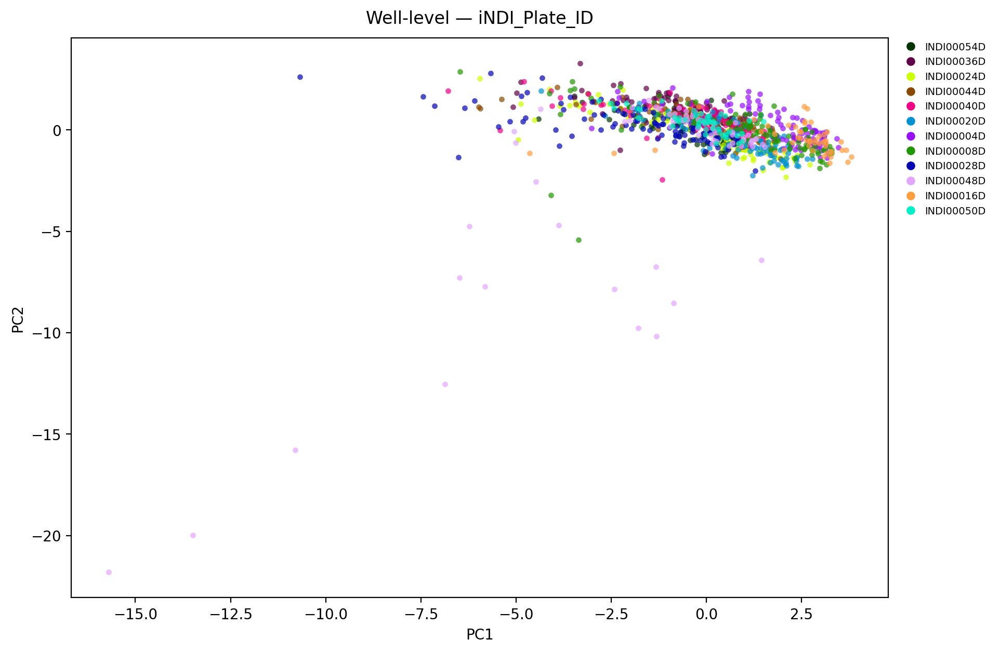

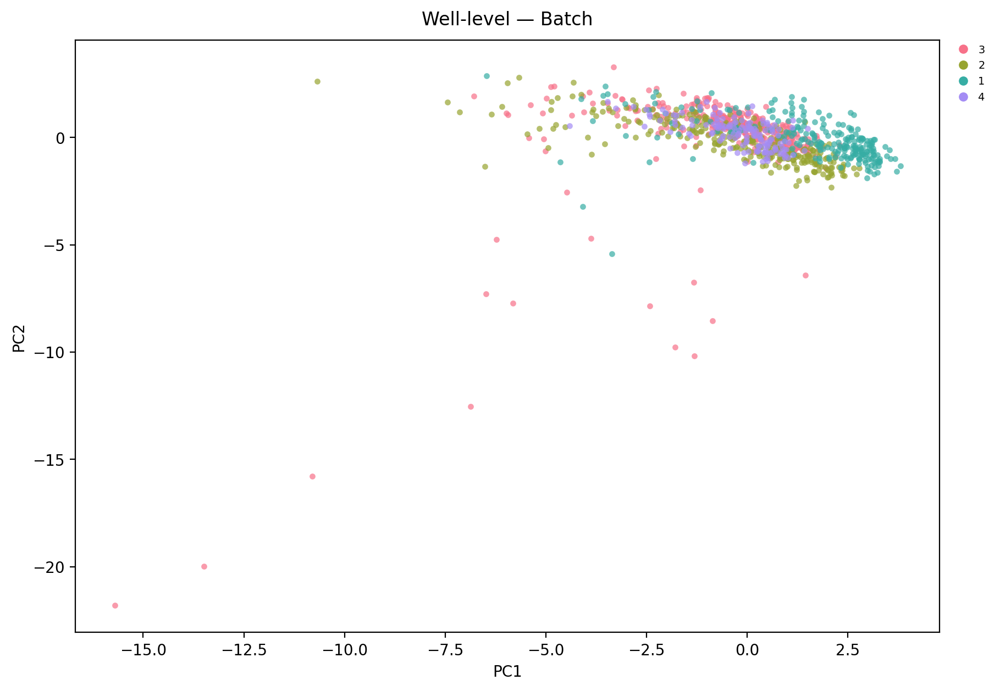

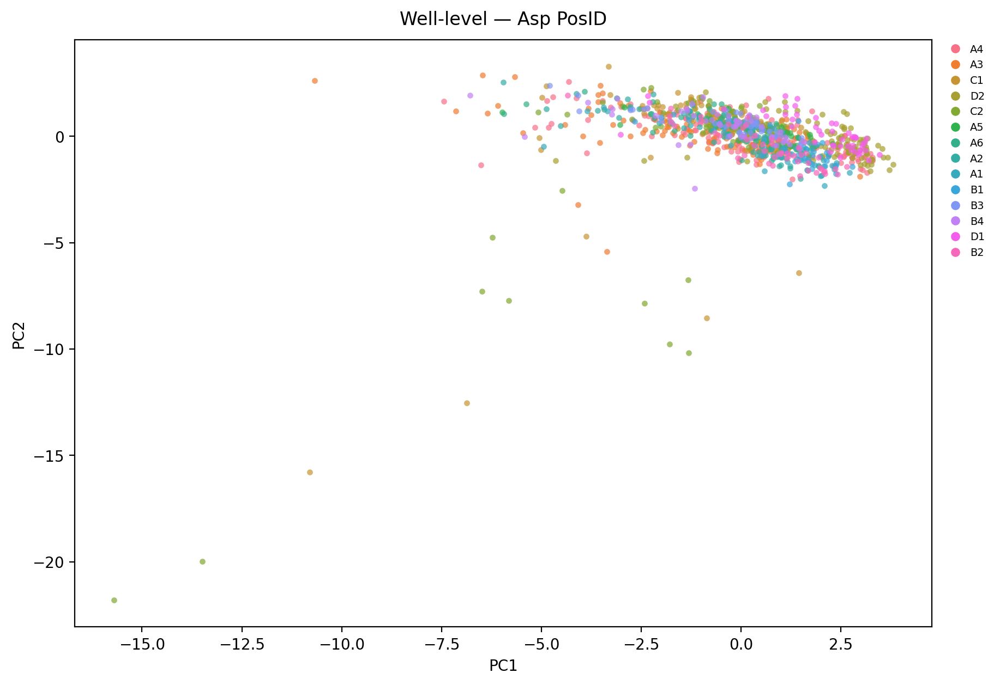

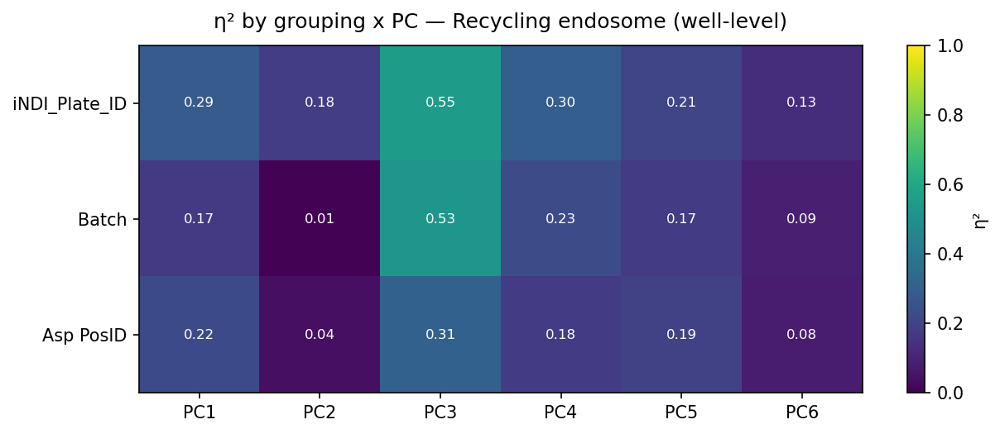

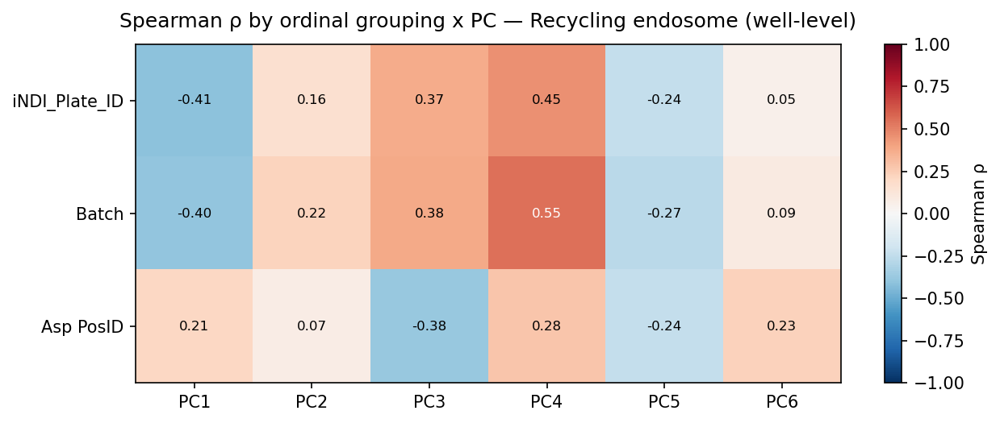

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.413978,0.163261,0.369846,0.454081,-0.240541,0.052519
Batch,-0.397571,0.221000,0.376685,0.547369,-0.268069,0.086568
Asp PosID,0.205097,0.071404,-0.380039,0.279256,-0.237967,0.232299


In [17]:
well_level = aggregate_wells(parental, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — Recycling endosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Recycling endosome (well-level)")

In [18]:
build_pptx("/data/kelpschdj/iNDI/Production/notebooks/analysis_xanf/xanf_RecyclingEndosome_analysis.pptx")

wrote 117 slides -> /data/kelpschdj/iNDI/Production/notebooks/analysis_xanf/xanf_RecyclingEndosome_analysis.pptx
